# スライド掲載プロット再現 Notebook (`plot_slides.ipynb`)

`results/csv/` に格納された集計済み CSV から、発表スライド（本編 P.17〜20・Appendix P.22〜26）の全プロットを `results/figures/{png,pdf}/` に再描画します。  
末尾のセルでは、OpenQARP（`openqarp`）が導入されている環境で P.14 の XY-QAOA 回路図も生成できます。

| 実験内容 | 元 CSV (`results/csv/`) | 出力図 (`results/figures/`) |
|---|---|---|
| 固定 FM: SA ペナルティ係数 $lpha$ 掃引（$L=6	ext{--}8$） | `fixedfm_sa_alpha_sweep.csv` | `fixedfm_sa_alpha_sweep` |
| 固定 FM: XY-QAOA 深さ $p$ 掃引（$L=6	ext{--}8$） | `fixedfm_xy_depth_sweep.csv` | `fixedfm_xy_depth_sweep` |
| 閉ループ BBO: SA $lpha$ 掃引（$L=7$, 15 seeds） | `closedloop_l7_alpha_sweep.csv` | `closedloop_l7_alpha_sweep` |
| 閉ループ BBO: 3層数統一比較（$L=6,7,8$, 各 30 seeds） | `closedloop_l678_fom_curves.csv` | `closedloop_l678_fom_curves` |
| 固定 FM: 実行可能サンプルの FM 百分位分布（$L=7$） | `fixedfm_l7_percentile_hist.csv` | `fixedfm_l7_percentile_hist` |
| 頑健性検証: SA 温度再設定・10倍 sweeps | `fixedfm_sa_schedule_retune.csv`, `closedloop_l7_schedule_retune.csv` | `sa_schedule_retune_robustness` |
| 閉ループ BBO: 第1確認実験の Seed 対応（$L=7$, 15 seeds） | `closedloop_l7_paired_ranks.csv` | `closedloop_l7_paired_ranks` |
| 閉ループ BBO: 探索段階の推移（$L=6,7,8$, 5 seeds） | `closedloop_l678_explore_5seeds.csv` | `closedloop_l678_explore_5seeds` |
| 固定 FM: SA `reads` 掃引（$L=7$, 100〜10,000 reads） | `fixedfm_l7_sa_reads_sweep.csv` | `fixedfm_l7_sa_reads_sweep` |
| OpenQARP: XY-QAOA 回路図（`openqarp` 導入環境のみ） | （回路構築） | `openqarp_xy_qaoa_macro`, `openqarp_xy_mixer_decomp` |


In [1]:
from pathlib import Path
import csv

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from IPython.display import Image as IPImage, display

ROOT = Path.cwd()
if not (ROOT / "results" / "csv").exists() and (ROOT.parent / "results" / "csv").exists():
    ROOT = ROOT.parent

CSV_DIR = ROOT / "results" / "csv"
FIG_DIR = ROOT / "results" / "figures"
(FIG_DIR / "png").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "pdf").mkdir(parents=True, exist_ok=True)

AVAILABLE_FONTS = {f.name for f in font_manager.fontManager.ttflist}
SERIF_FAMILY = "Liberation Serif" if "Liberation Serif" in AVAILABLE_FONTS else "STIXGeneral"

SLIDE_RC = {
    "font.family": "serif",
    "font.serif": [SERIF_FAMILY, "STIXGeneral", "DejaVu Serif"],
    "font.size": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "mathtext.fontset": "stix",
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "axes.unicode_minus": False,
    "legend.frameon": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
}

BLUE, ORANGE, GREEN, PURPLE, GRAY = "#2a78d6", "#e8682f", "#1a9e6e", "#7b4fb3", "#8c8c8c"
M = {
    "XY-FMQAOA": dict(color=BLUE, ls="-", lw=3.0, label="XY-FMQAOA ($\\lambda=0$)"),
    "alpha1": dict(color="black", ls="--", lw=2.0, label="SA, $\\alpha=1$ (tuned)"),
    "alpha100": dict(color=ORANGE, ls="-", lw=2.0, label="SA, $\\alpha=100$ (too large)"),
    "alpha0.3": dict(color=GREEN, ls="-.", lw=2.0, label="SA, $\\alpha=0.3$ (too small)"),
    "CatSA": dict(color=PURPLE, ls=":", lw=2.4, label="Categorical SA"),
    "RandomFM": dict(color=GRAY, ls="--", lw=1.6, label="Random proposals + FM selection"),
    "Random": dict(color=GRAY, ls=":", lw=1.8, label="Random search"),
}

FW, FH = 7.4, 5.0
ALPHAS = [0.3, 1, 3, 10, 30, 100, 1000]
ATICK = ["0.3", "1", "3", "10", "30", "100", "1000"]
NCAND = {6: "4,096", 7: "16,384", 8: "65,536"}


def read_csv(name: str) -> list[dict]:
    def conv(v: str):
        if v == "":
            return None
        try:
            return float(v)
        except ValueError:
            return v

    with open(CSV_DIR / name, encoding="utf-8") as f:
        return [{k: conv(v) for k, v in row.items()} for row in csv.DictReader(f)]


def save_and_show(fig, stem: str, width: int = 720) -> None:
    png_path = FIG_DIR / "png" / f"{stem}.png"
    pdf_path = FIG_DIR / "pdf" / f"{stem}.pdf"
    fig.savefig(png_path, facecolor="white")
    fig.savefig(pdf_path, facecolor="white")
    plt.close(fig)
    Image.open(png_path).convert("RGB").save(png_path)
    print(f"Saved: {png_path.relative_to(ROOT)}, {pdf_path.relative_to(ROOT)}")
    display(IPImage(filename=str(png_path), width=width))


def alpha_axis(ax) -> None:
    ax.set_xscale("log")
    ax.set_xticks(ALPHAS)
    ax.set_xticklabels(ATICK)
    ax.minorticks_off()
    ax.set_xlim(0.22, 1400)


def log_ticks(axis, ticks) -> None:
    axis.set_ticks(ticks)
    axis.set_ticklabels([f"{t:g}" for t in ticks])
    axis.set_minor_locator(matplotlib.ticker.NullLocator())


def letters(axes, x: float = -0.02, y: float = 1.02) -> None:
    for ax, t in zip(axes, "abcdefgh"):
        ax.text(x, y, f"({t})", transform=ax.transAxes, ha="right", va="bottom", fontsize=13)


print(f"CSV_DIR: {CSV_DIR.relative_to(ROOT)} ({len(list(CSV_DIR.glob('*.csv')))} files)")
print(f"Font: {SERIF_FAMILY}")


CSV_DIR: results/csv (10 files)
Font: STIXGeneral


## 1. 固定 FM: ペナルティ係数 $\alpha$ と SA の出力品質（固定 FM, $L=6\text{--}8$）

学習済み FM を固定し、SA（100 reads × 1000 sweeps）の出力品質を $\alpha$ ごとに評価した結果（5 FM の中央値）。


Saved: results/figures/png/fixedfm_sa_alpha_sweep.png, results/figures/pdf/fixedfm_sa_alpha_sweep.pdf


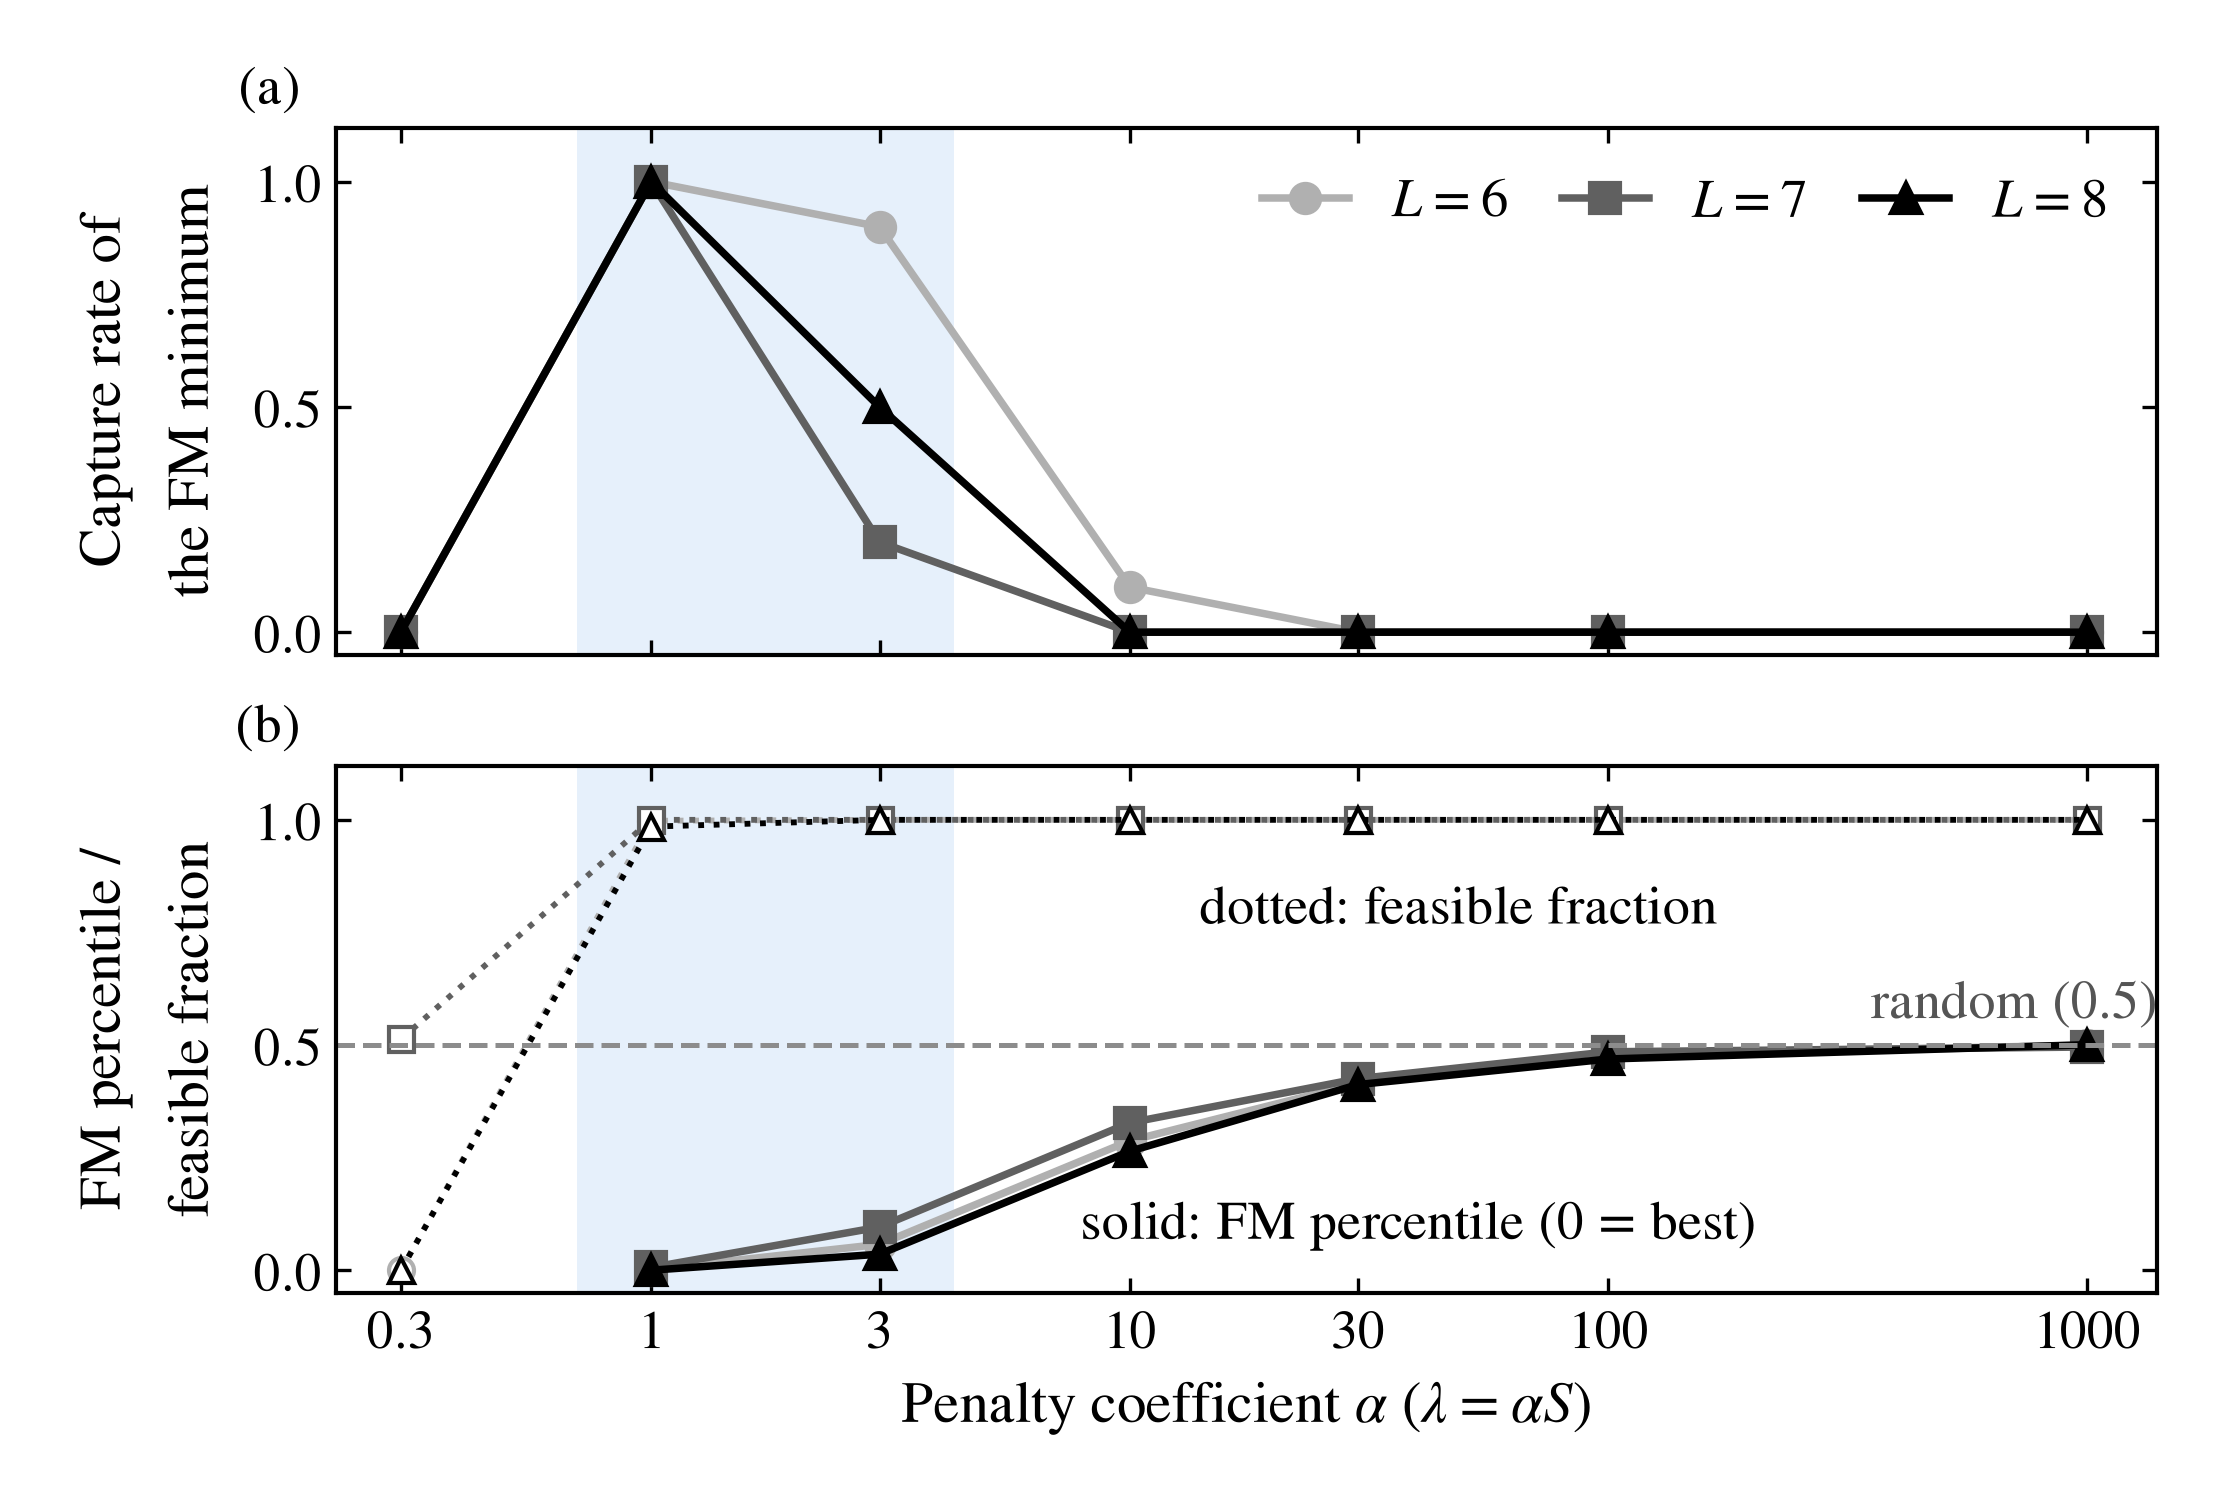

In [2]:
rows = read_csv("fixedfm_sa_alpha_sweep.csv")
with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(2, 1, figsize=(FW, FH), sharex=True)
    shades = {6: ("#b0b0b0", "o"), 7: ("#606060", "s"), 8: ("black", "^")}
    for ax in axes:
        ax.axvspan(0.7, 4.3, color="#e6f0fb", lw=0, zorder=0)
        alpha_axis(ax)
    for L, (c, mk) in shades.items():
        r = [x for x in rows if x["layers"] == L]
        col = lambda k: [np.nan if x[k] is None else x[k] for x in r]
        a = [x["alpha"] for x in r]
        axes[0].plot(a, col("capture_median"), color=c, marker=mk, ms=7, lw=1.8, label=f"$L={L}$")
        axes[1].plot(a, col("sample_fm_pct_median"), color=c, marker=mk, ms=7, lw=1.8)
        axes[1].plot(a, col("feasible_median"), color=c, marker=mk, ms=6, lw=1.4, ls=":", mfc="white")
    axes[0].set_ylabel("Capture rate of\nthe FM minimum")
    axes[0].set_ylim(-0.05, 1.12)
    axes[0].set_yticks([0, 0.5, 1])
    axes[0].legend(loc="upper right", ncol=3, handlelength=1.6, columnspacing=1.0, fontsize=13)
    axes[1].axhline(0.5, color=GRAY, ls="--", lw=1.2)
    axes[1].text(1400, 0.53, "random (0.5)", ha="right", va="bottom", fontsize=13, color="#555555")
    axes[1].text(40, 0.04, "solid: FM percentile (0 = best)", fontsize=13, va="bottom", ha="center")
    axes[1].text(14, 0.80, "dotted: feasible fraction", fontsize=13, va="center")
    axes[1].set_ylabel("FM percentile /\nfeasible fraction")
    axes[1].set_ylim(-0.05, 1.12)
    axes[1].set_yticks([0, 0.5, 1])
    axes[1].set_xlabel("Penalty coefficient $\\alpha$ ($\\lambda=\\alpha S$)")
    letters(axes)
    fig.tight_layout(h_pad=0.6)
    save_and_show(fig, "fixedfm_sa_alpha_sweep")


## 2. 固定 FM: XY-QAOA の深さ $p$ と正規化 FM ギャップ（固定 FM, $L=6\text{--}8$）

XY-FMQAOA（$\lambda=0, \mathrm{CVaR}_{0.1}$）の深さ $p=1\text{--}6$ に対する正規化 FM ギャップ（小さいほど良い）。


Saved: results/figures/png/fixedfm_xy_depth_sweep.png, results/figures/pdf/fixedfm_xy_depth_sweep.pdf


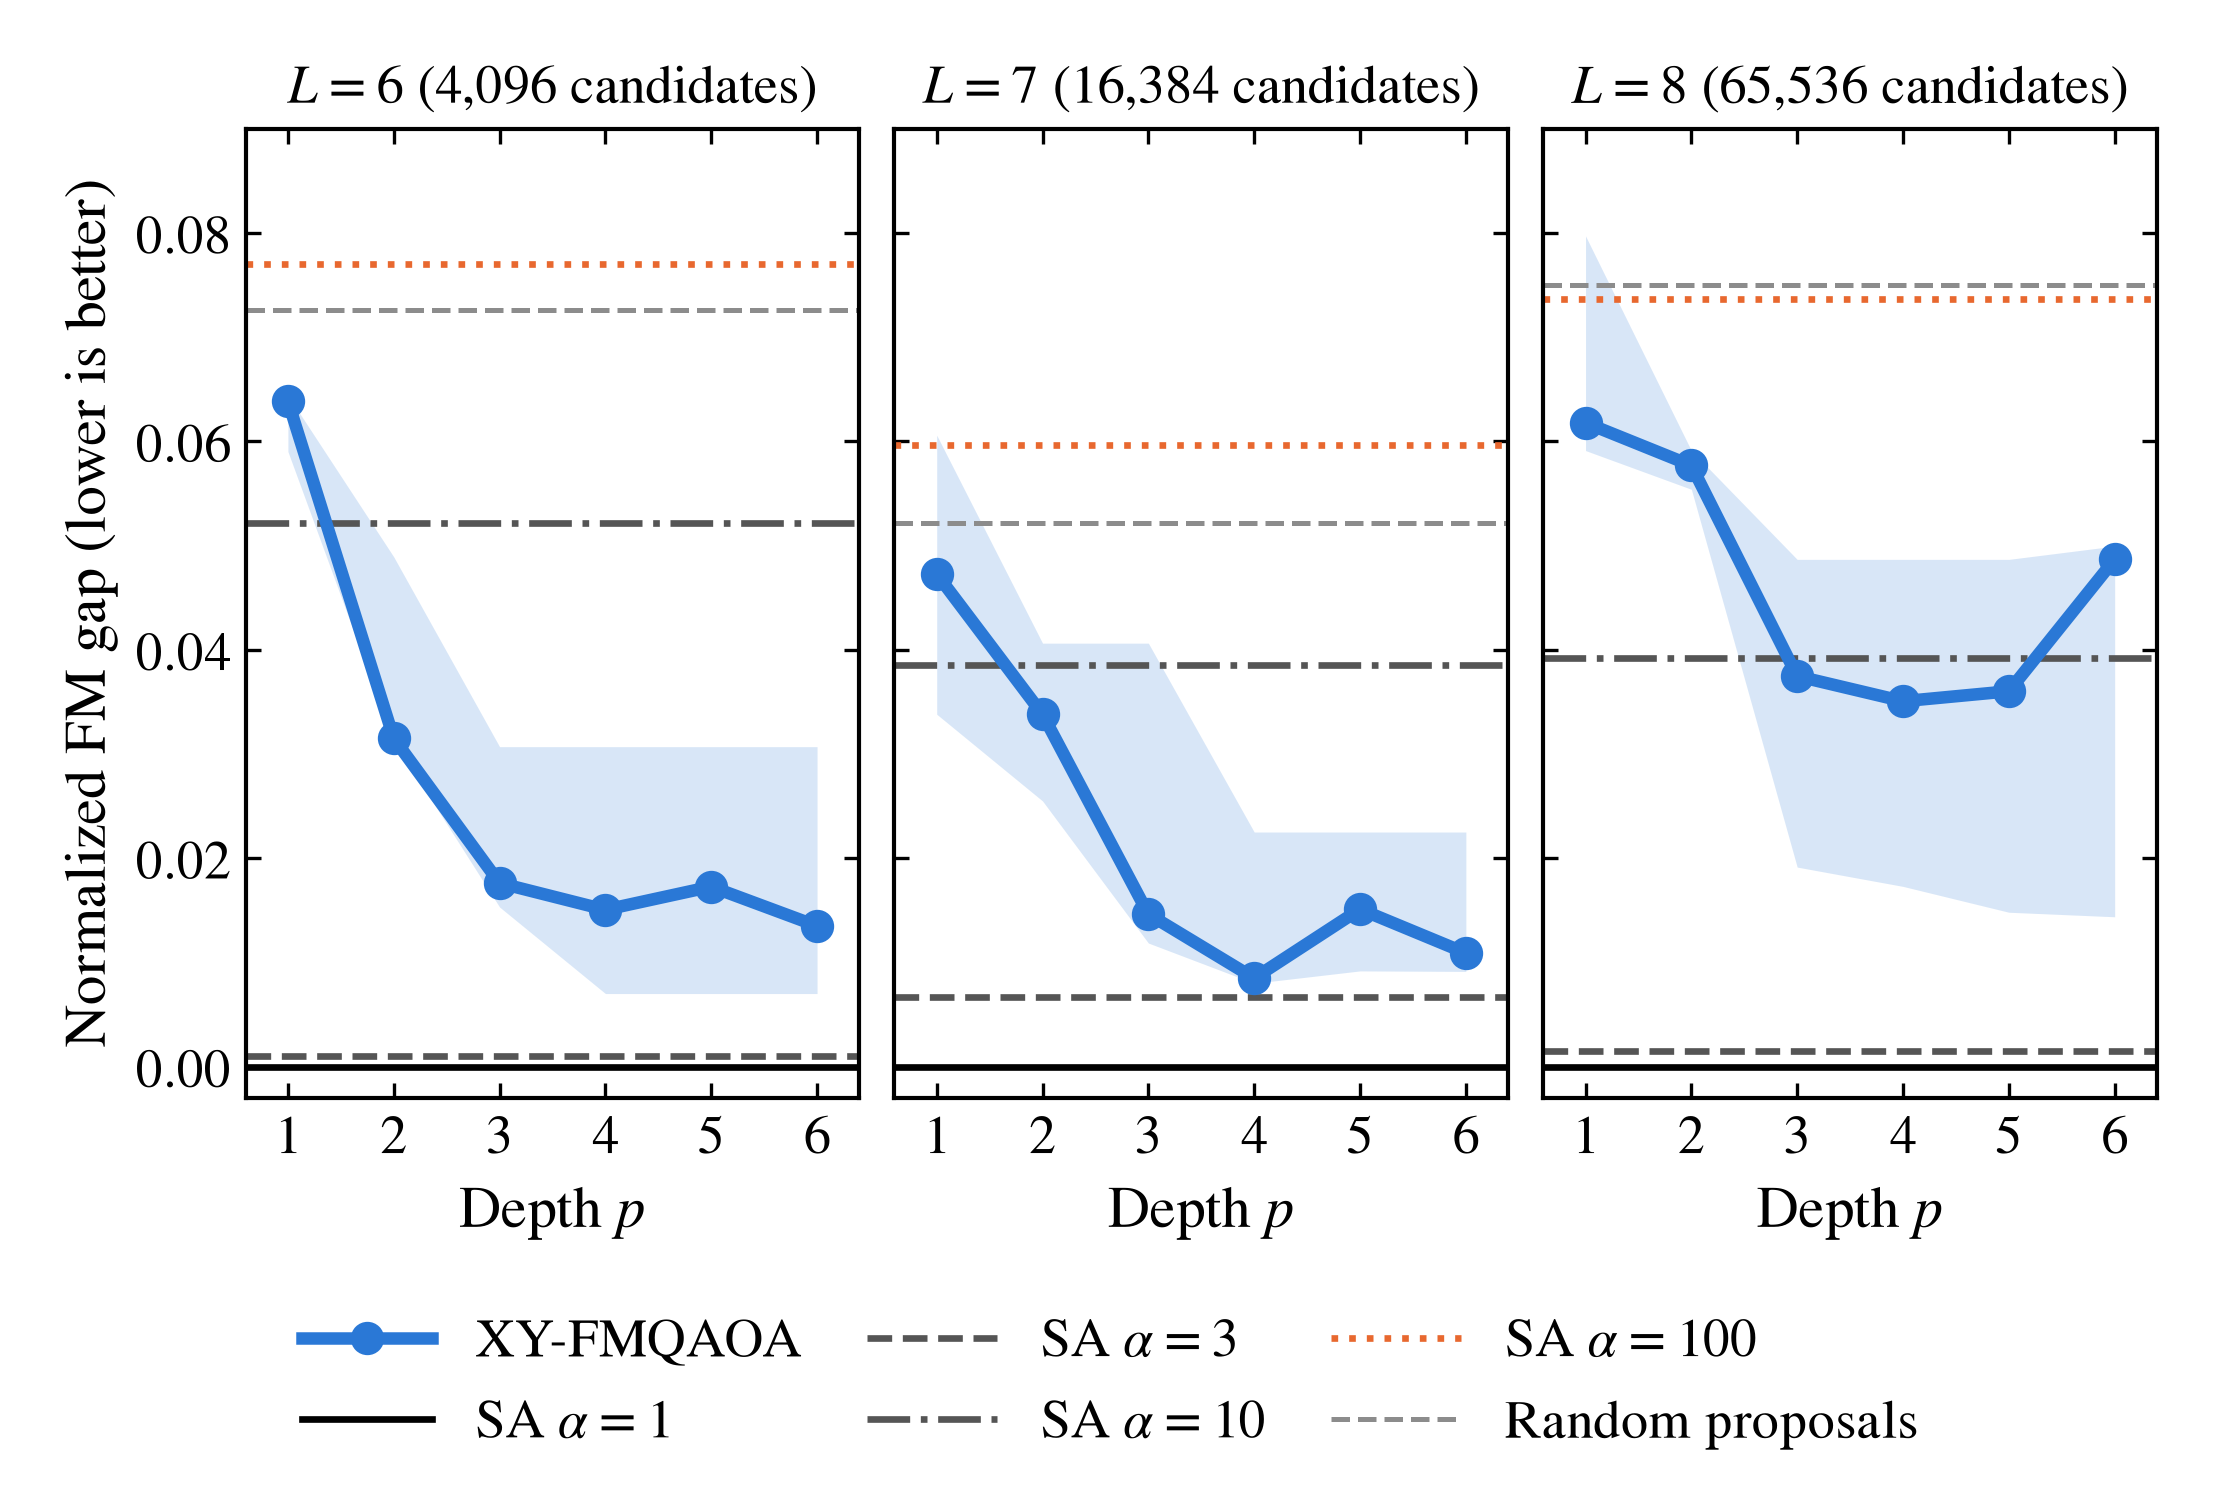

In [3]:
rows = read_csv("fixedfm_xy_depth_sweep.csv")
ref = {(int(r["layers"]), r["method"]): r["norm_gap_median"] for r in rows if r["method"] != "XY-FMQAOA"}
with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 3, figsize=(FW, FH), sharey=True)
    refs = [
        (1, "black", "-", "SA $\\alpha=1$"),
        (3, "#555555", "--", "SA $\\alpha=3$"),
        (10, "#555555", "-.", "SA $\\alpha=10$"),
        (100, ORANGE, ":", "SA $\\alpha=100$"),
    ]
    for ax, L in zip(axes, (6, 7, 8)):
        for a, c, ls, lab in refs:
            ax.axhline(ref[(L, f"SA-a{a}")], color=c, ls=ls, lw=1.6, label=lab)
        ax.axhline(ref[(L, "RandomFM")], color=GRAY, ls="--", lw=1.2, label="Random proposals")
        xy = sorted((r for r in rows if r["layers"] == L and r["method"] == "XY-FMQAOA"), key=lambda r: r["p"])
        p = np.array([r["p"] for r in xy])
        ax.fill_between(p, [r["norm_gap_q25"] for r in xy], [r["norm_gap_q75"] for r in xy], color=BLUE, alpha=0.18, lw=0)
        ax.plot(p, [r["norm_gap_median"] for r in xy], color=BLUE, lw=3.0, marker="o", ms=7, label="XY-FMQAOA")
        ax.set_xticks(p)
        ax.set_xlim(0.6, 6.4)
        ax.set_ylim(-0.003, 0.09)
        ax.set_title(f"$L={L}$ ({NCAND[L]} candidates)", fontsize=13)
        ax.set_xlabel("Depth $p$")
    axes[0].set_ylabel("Normalized FM gap (lower is better)")
    h, l = axes[0].get_legend_handles_labels()
    order = [5, 0, 1, 2, 3, 4]
    fig.legend([h[i] for i in order], [l[i] for i in order], loc="lower center", ncol=3, fontsize=13, handlelength=2.4, columnspacing=1.2)
    fig.tight_layout(rect=(0, 0.13, 1, 1), w_pad=0.6)
    save_and_show(fig, "fixedfm_xy_depth_sweep")


## 3. 閉ループ BBO:  $\alpha$ 掃引（$L=7$, 15 seeds, 予算 100）

FMQA サイクルを 100 回評価まで回したときの最良解の真の順位（1 = 最適解）と、最適解到達 Seed 数（/15）。


Saved: results/figures/png/closedloop_l7_alpha_sweep.png, results/figures/pdf/closedloop_l7_alpha_sweep.pdf


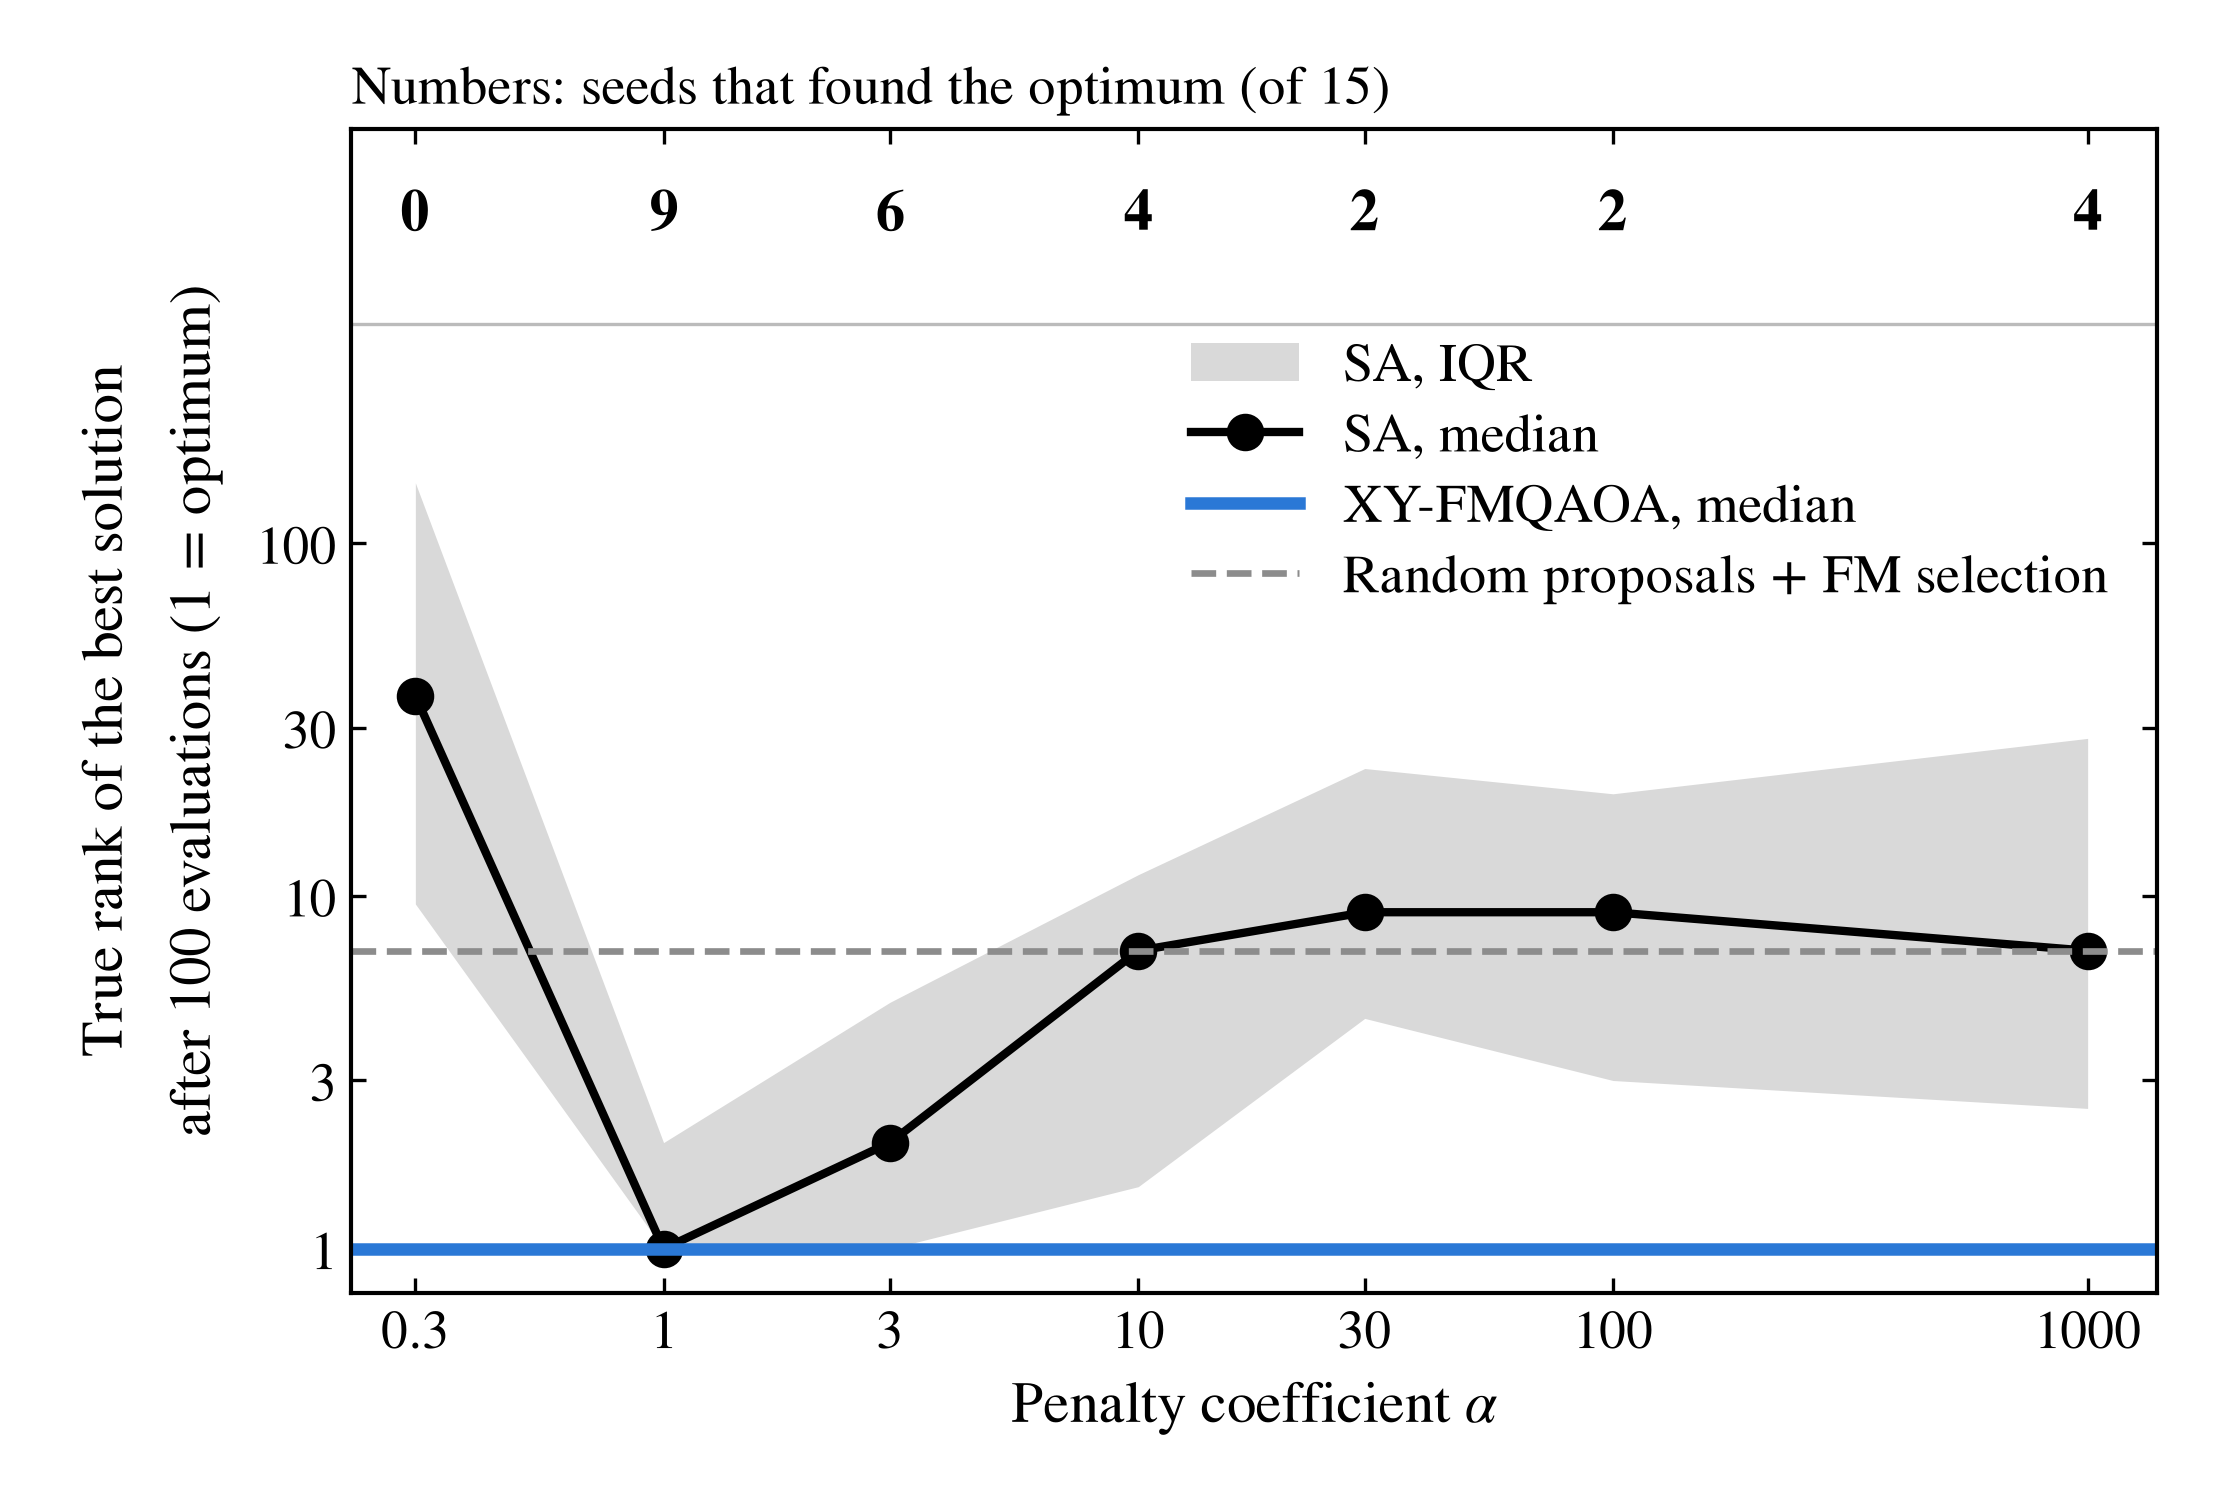

In [4]:
rows = read_csv("closedloop_l7_alpha_sweep.csv")
by = {r["condition"]: r for r in rows}
sa = [by[f"alpha{a:g}"] for a in ALPHAS]
with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(FW, FH))
    ax.fill_between(ALPHAS, [r["best_rank_q25"] for r in sa], [r["best_rank_q75"] for r in sa], color="#d9d9d9", lw=0, label="SA, IQR")
    ax.plot(ALPHAS, [r["best_rank_median"] for r in sa], color="black", marker="o", ms=8, lw=2.0, label="SA, median")
    ax.axhline(by["XY-FMQAOA"]["best_rank_median"], color=BLUE, lw=3.0, label="XY-FMQAOA, median")
    ax.axhline(by["RandomFM"]["best_rank_median"], color=GRAY, ls="--", lw=1.6, label="Random proposals + FM selection")
    ax.set_yscale("log")
    ax.set_ylim(0.75, 1500)
    log_ticks(ax.yaxis, [1, 3, 10, 30, 100])
    alpha_axis(ax)
    ax.set_xlabel("Penalty coefficient $\\alpha$")
    ax.set_ylabel("True rank of the best solution\nafter 100 evaluations (1 = optimum)")
    for a, r in zip(ALPHAS, sa):
        ax.text(a, 850, f"{int(r['n_optimum'])}", ha="center", va="center", fontsize=14, fontweight="bold")
    ax.axhline(420, color="#bbbbbb", lw=0.8)
    ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.86), fontsize=13, labelspacing=0.3)
    ax.set_title("Numbers: seeds that found the optimum (of 15)", fontsize=13, loc="left")
    fig.tight_layout()
    save_and_show(fig, "closedloop_l7_alpha_sweep")


## 4. 閉ループ BBO: 3層数統一比較（$L=6, 7, 8$, 各 30 seeds）

3つの層数（$L=6,7$: 予算 100, $L=8$: 予算 200）における最良 FOM の推移（中央値・XY の IQR）と最適解到達 Seed 数（右上インセット）。


Saved: results/figures/png/closedloop_l678_fom_curves.png, results/figures/pdf/closedloop_l678_fom_curves.pdf


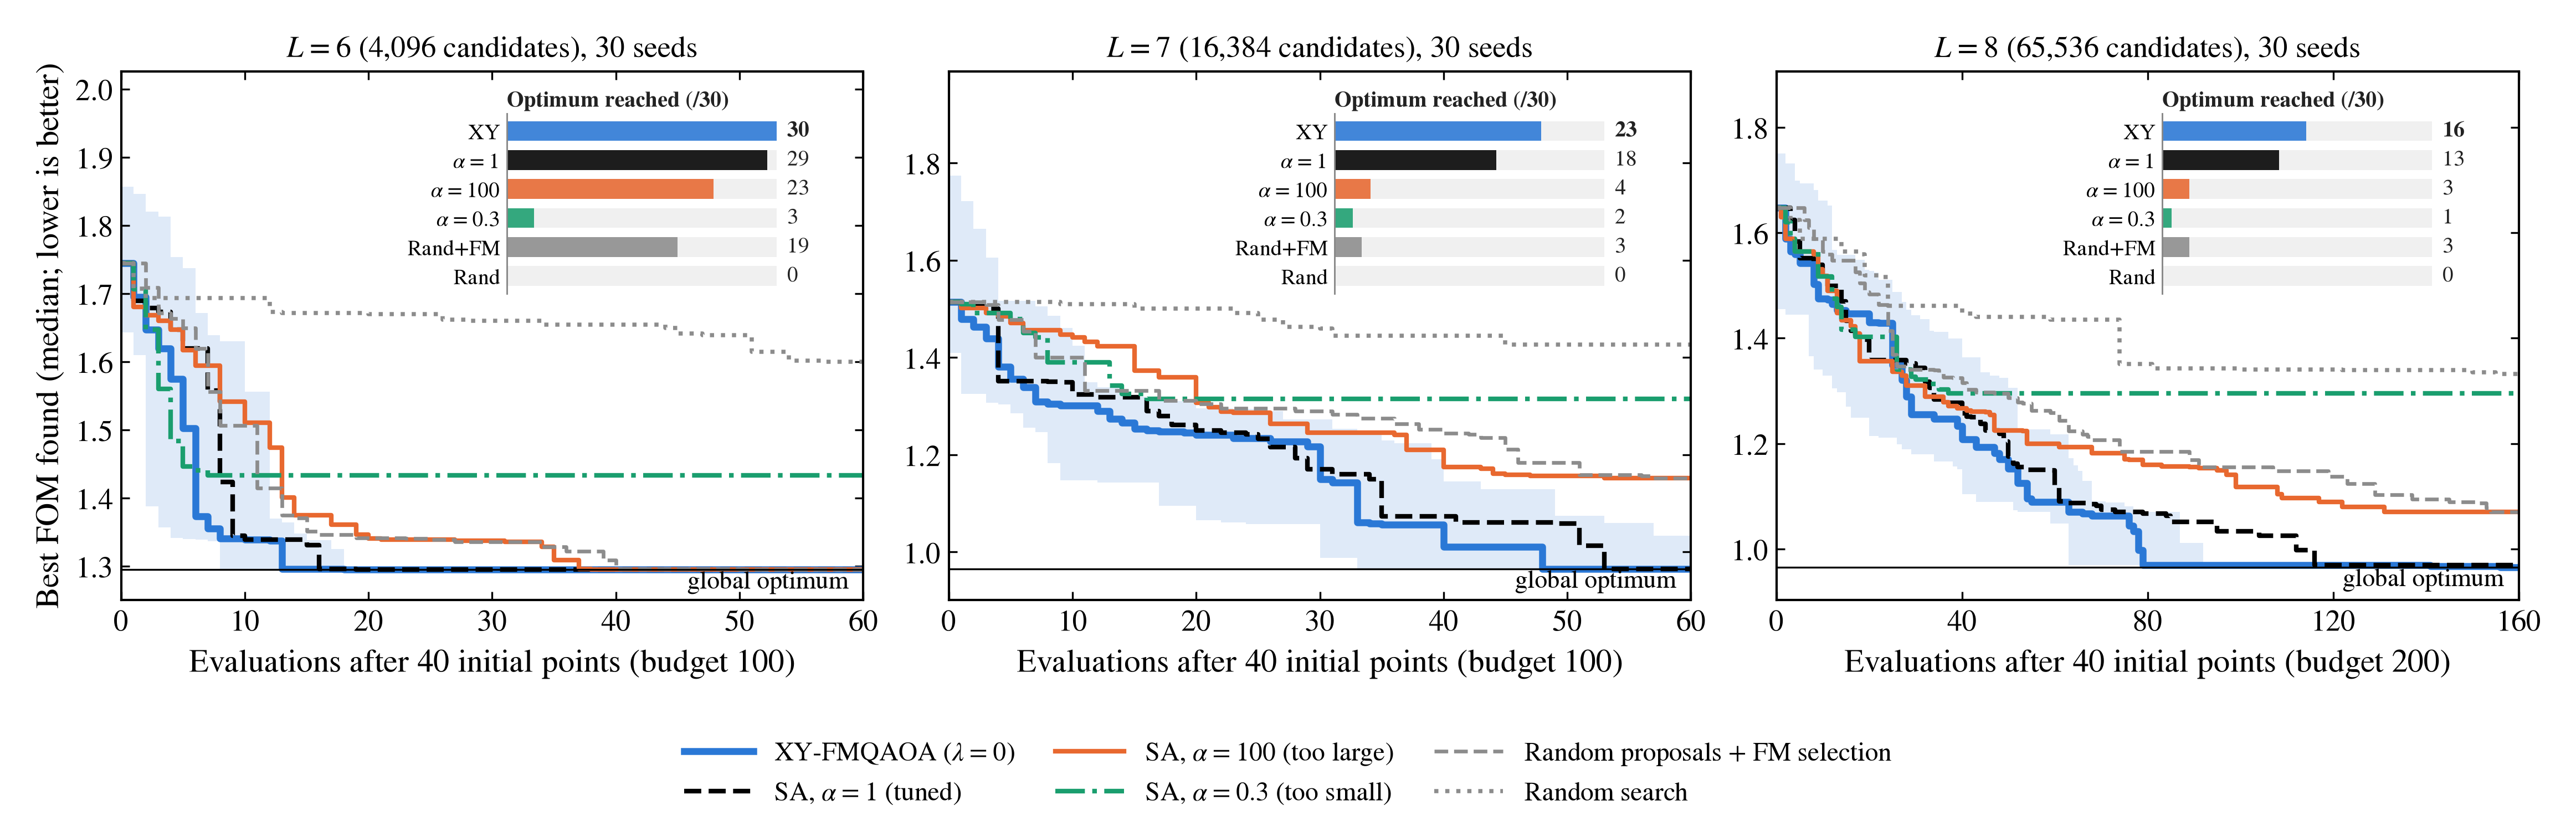

In [5]:
rows = read_csv("closedloop_l678_fom_curves.csv")
FIG_L678_METHODS = ["XY-FMQAOA", "alpha1", "alpha100", "alpha0.3", "RandomFM", "Random"]
SHORT_NAME = {
    "XY-FMQAOA": "XY",
    "alpha1": "$\\alpha=1$",
    "alpha100": "$\\alpha=100$",
    "alpha0.3": "$\\alpha=0.3$",
    "RandomFM": "Rand+FM",
    "Random": "Rand",
}

with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0))
    for ax, L in zip(axes, (6, 7, 8)):
        sub = [x for x in rows if x["layers"] == L and x["condition"] in FIG_L678_METHODS]
        last = int(max(x["cycle"] for x in sub))
        ns = max(int(x["n_seeds"]) for x in sub)
        hits = []
        for c in FIG_L678_METHODS:
            r = sorted((x for x in sub if x["condition"] == c), key=lambda x: x["cycle"])
            if not r:
                continue
            st = M[c]
            cyc = [x["cycle"] for x in r]
            if c == "XY-FMQAOA":
                ax.fill_between(cyc, [x["best_fom_q25"] for x in r], [x["best_fom_q75"] for x in r], step="post", color=st["color"], alpha=0.15, lw=0)
            ax.step(cyc, [x["best_fom_median"] for x in r], where="post", color=st["color"], ls=st["ls"], lw=st["lw"], label=st["label"])
            hits.append((c, st["color"], int(r[-1]["n_optimum"]), int(r[-1]["n_seeds"])))
        opt = sub[0]["global_optimum_fom"]
        ax.axhline(opt, color="black", lw=0.8)
        top = max([x["best_fom_q75"] for x in sub if x["condition"] == "XY-FMQAOA"] + [x["best_fom_median"] for x in sub])
        right_max = max(x["best_fom_median"] for x in sub if x["cycle"] >= 0.42 * last)
        y_lo = opt - 0.08 * (top - opt)
        y_hi_for_inset = y_lo + (right_max - y_lo) / 0.53
        y_hi = max(top + 0.04 * (top - opt), y_hi_for_inset)
        ax.set_ylim(y_lo, y_hi)
        ax.text(last * 0.98, opt, "global optimum", ha="right", va="top", fontsize=11)
        ax.set_xlim(0, last)
        ax.set_xticks(range(0, last + 1, 40 if last > 60 else 10))
        ax.set_xlabel(f"Evaluations after 40 initial points (budget {last + 40})")
        ax.set_title(f"$L={L}$ ({NCAND[L]} candidates), {ns} seeds", fontsize=13)

        ins = ax.inset_axes([0.52, 0.58, 0.45, 0.34])
        ins.set_facecolor("white")
        y_pos = np.arange(len(hits))[::-1]
        ins.barh(y_pos, [ns] * len(hits), height=0.68, color="#f0f0f0", edgecolor="none", zorder=1)
        ins.barh(y_pos, [h[2] for h in hits], height=0.68, color=[h[1] for h in hits], alpha=0.88, edgecolor="none", zorder=2)
        for yp, (c, col, n_opt, n_s) in zip(y_pos, hits):
            ins.text(ns + 1.2, yp, f"{n_opt}", va="center", ha="left", fontsize=9.5, color="#222222", fontweight="bold" if c == "XY-FMQAOA" else "normal")
        ins.set_yticks(y_pos)
        ins.set_yticklabels([SHORT_NAME[h[0]] for h in hits], fontsize=9.5)
        ins.set_xlim(0, ns * 1.24)
        ins.set_ylim(-0.6, len(hits) - 0.4)
        ins.set_xticks([])
        ins.tick_params(axis="y", length=0, pad=3, right=False)
        ins.tick_params(axis="x", bottom=False, top=False)
        for sp in ("top", "right", "bottom"):
            ins.spines[sp].set_visible(False)
        ins.spines["left"].set_color("#888888")
        ins.spines["left"].set_linewidth(0.7)
        ins.set_title(f"Optimum reached (/{ns})", fontsize=9.5, pad=3, loc="left", fontweight="bold", color="#222222")

    axes[0].set_ylabel("Best FOM found (median; lower is better)")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, fontsize=11.5, handlelength=2.6, columnspacing=1.5)
    fig.tight_layout(rect=(0, 0.14, 1, 1), w_pad=0.8)
    save_and_show(fig, "closedloop_l678_fom_curves", width=960)


## 5. 固定 FM: 実行可能サンプルの FM 百分位分布（固定 FM, $L=7$）


Saved: results/figures/png/fixedfm_l7_percentile_hist.png, results/figures/pdf/fixedfm_l7_percentile_hist.pdf


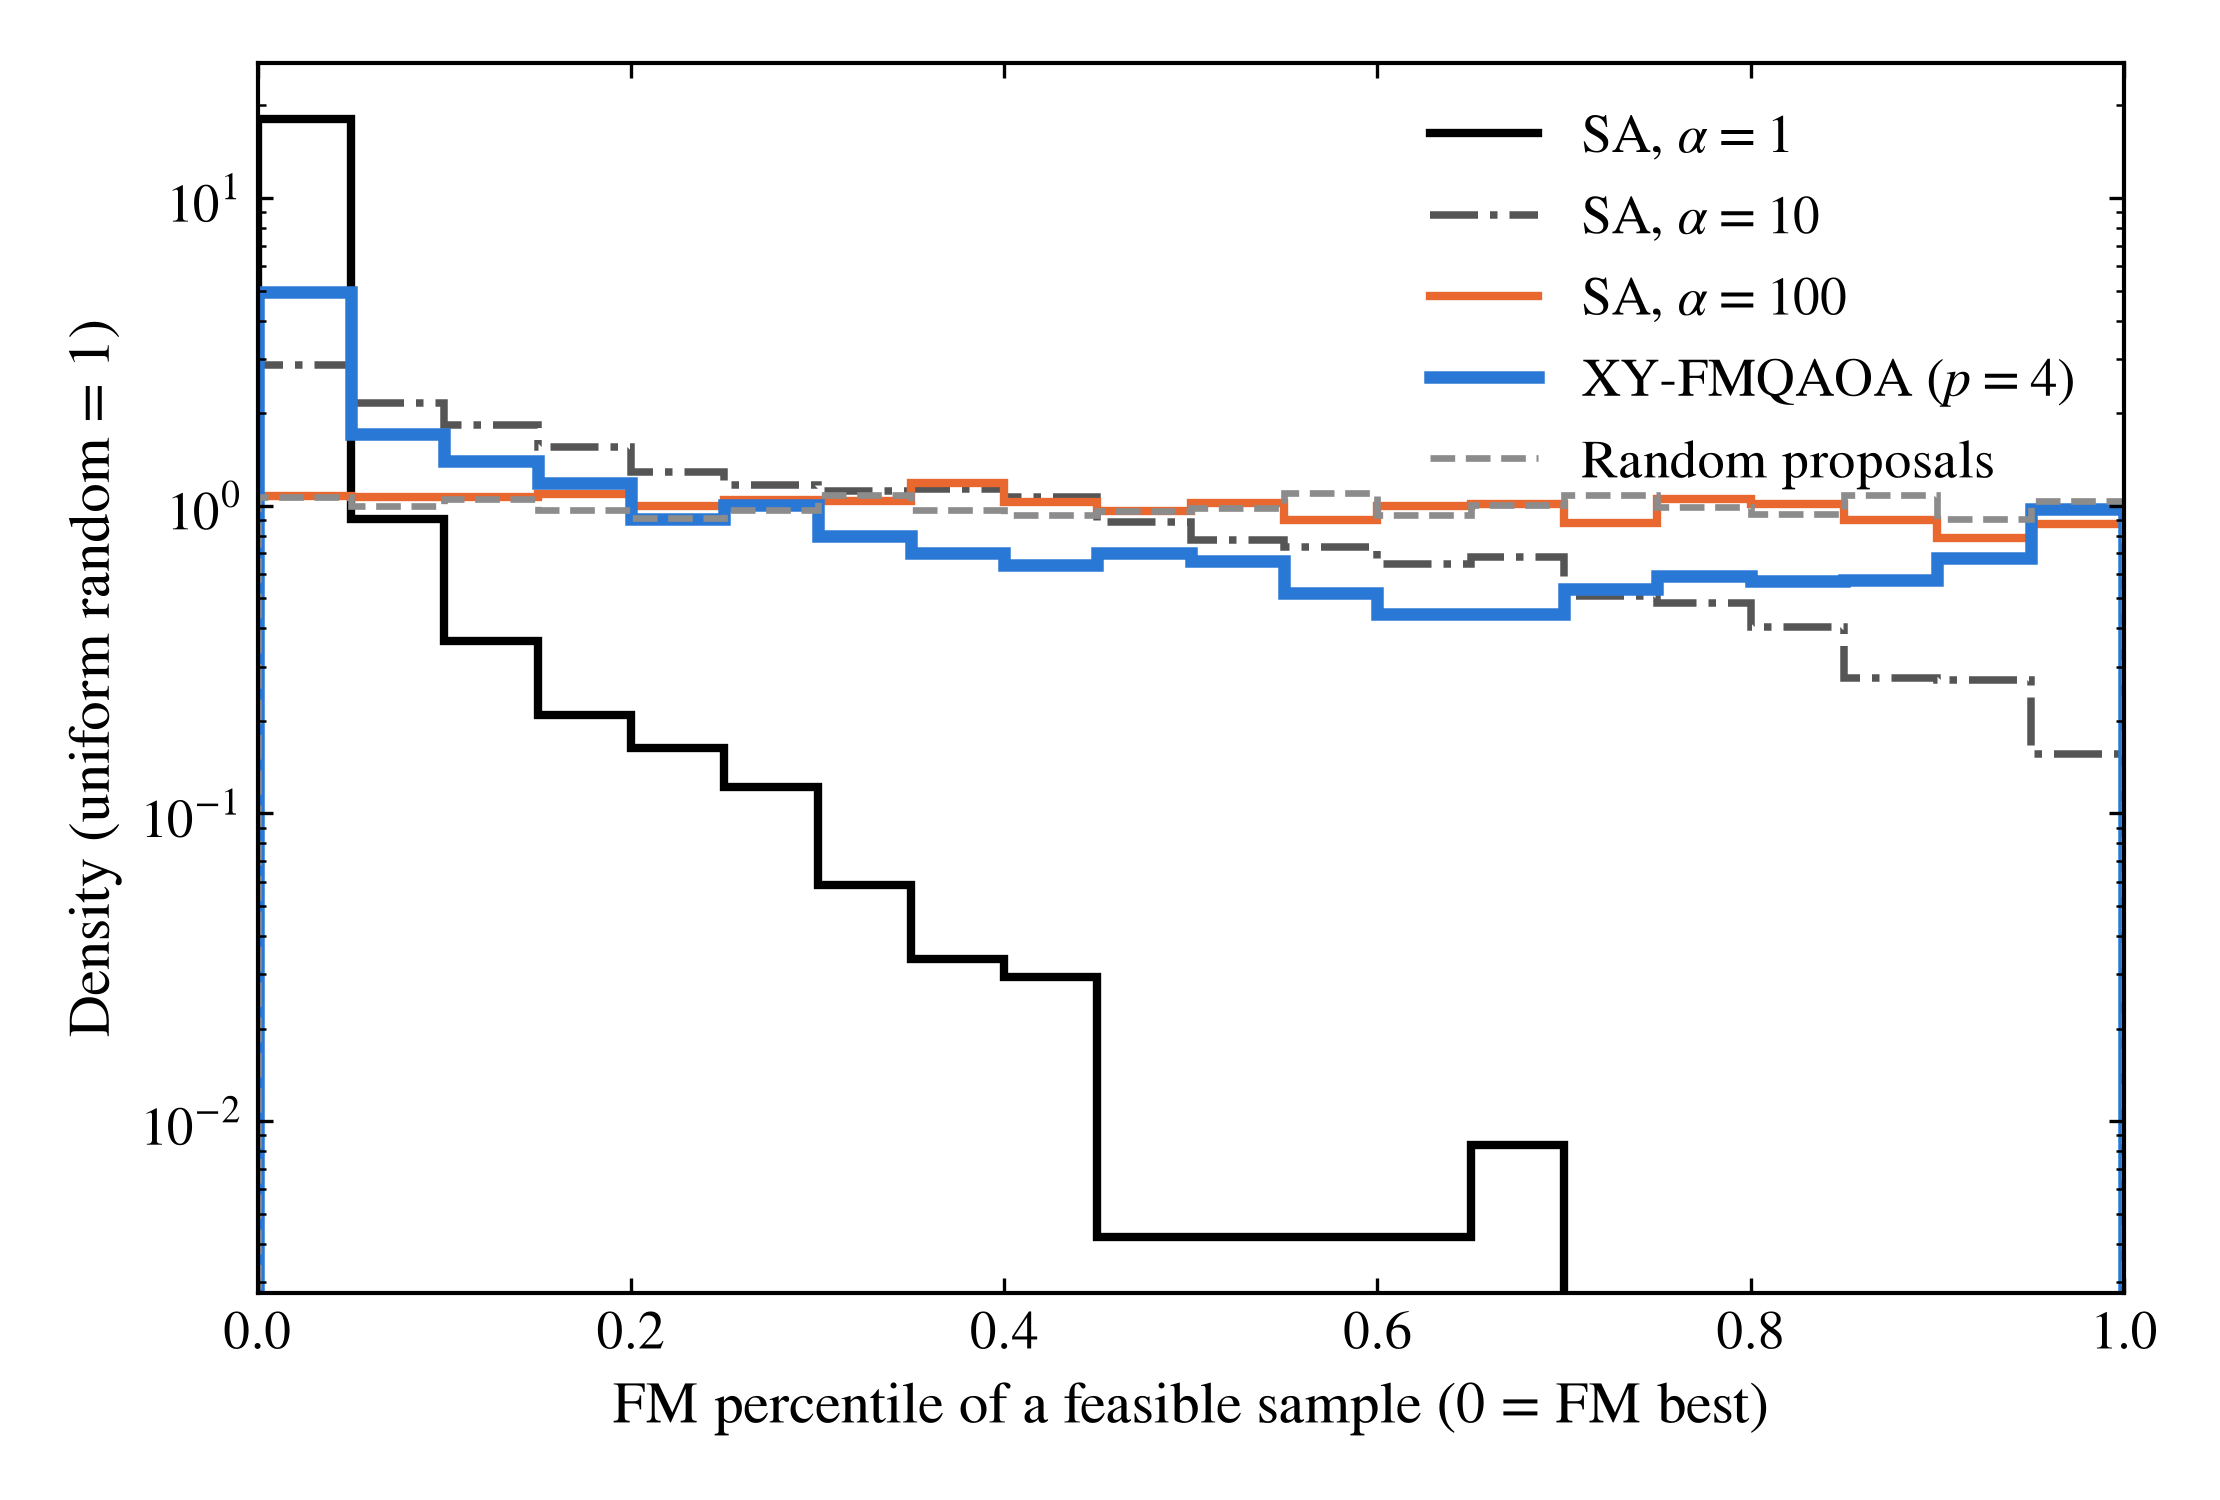

In [6]:
rows = read_csv("fixedfm_l7_percentile_hist.csv")
samplers = [
    ("SA-auto-a1", "SA, $\\alpha=1$", dict(color="black", ls="-", lw=2.0)),
    ("SA-auto-a10", "SA, $\\alpha=10$", dict(color="#555555", ls="-.", lw=1.8)),
    ("SA-auto-a100", "SA, $\\alpha=100$", dict(color=ORANGE, ls="-", lw=2.0)),
    ("XY-p4-cvar10", "XY-FMQAOA ($p=4$)", dict(color=BLUE, ls="-", lw=3.0)),
    ("RandomFM", "Random proposals", dict(color=GRAY, ls="--", lw=1.6)),
]
with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(FW, FH))
    for key, lab, st in samplers:
        r = sorted((x for x in rows if x["sampler"] == key), key=lambda x: x["bin_lo"])
        edges = np.append([x["bin_lo"] for x in r], 1.0)
        ax.stairs([x["density"] for x in r], edges, label=lab, **st)
    ax.set_yscale("log")
    ax.set_xlim(0, 1)
    ax.set_xlabel("FM percentile of a feasible sample (0 = FM best)")
    ax.set_ylabel("Density (uniform random = 1)")
    ax.legend(loc="upper right", fontsize=13)
    fig.tight_layout()
    save_and_show(fig, "fixedfm_l7_percentile_hist")


## 6. 頑健性検証: SA 温度スケジュール再設定・10倍 sweeps に対する頑健性


Saved: results/figures/png/sa_schedule_retune_robustness.png, results/figures/pdf/sa_schedule_retune_robustness.pdf


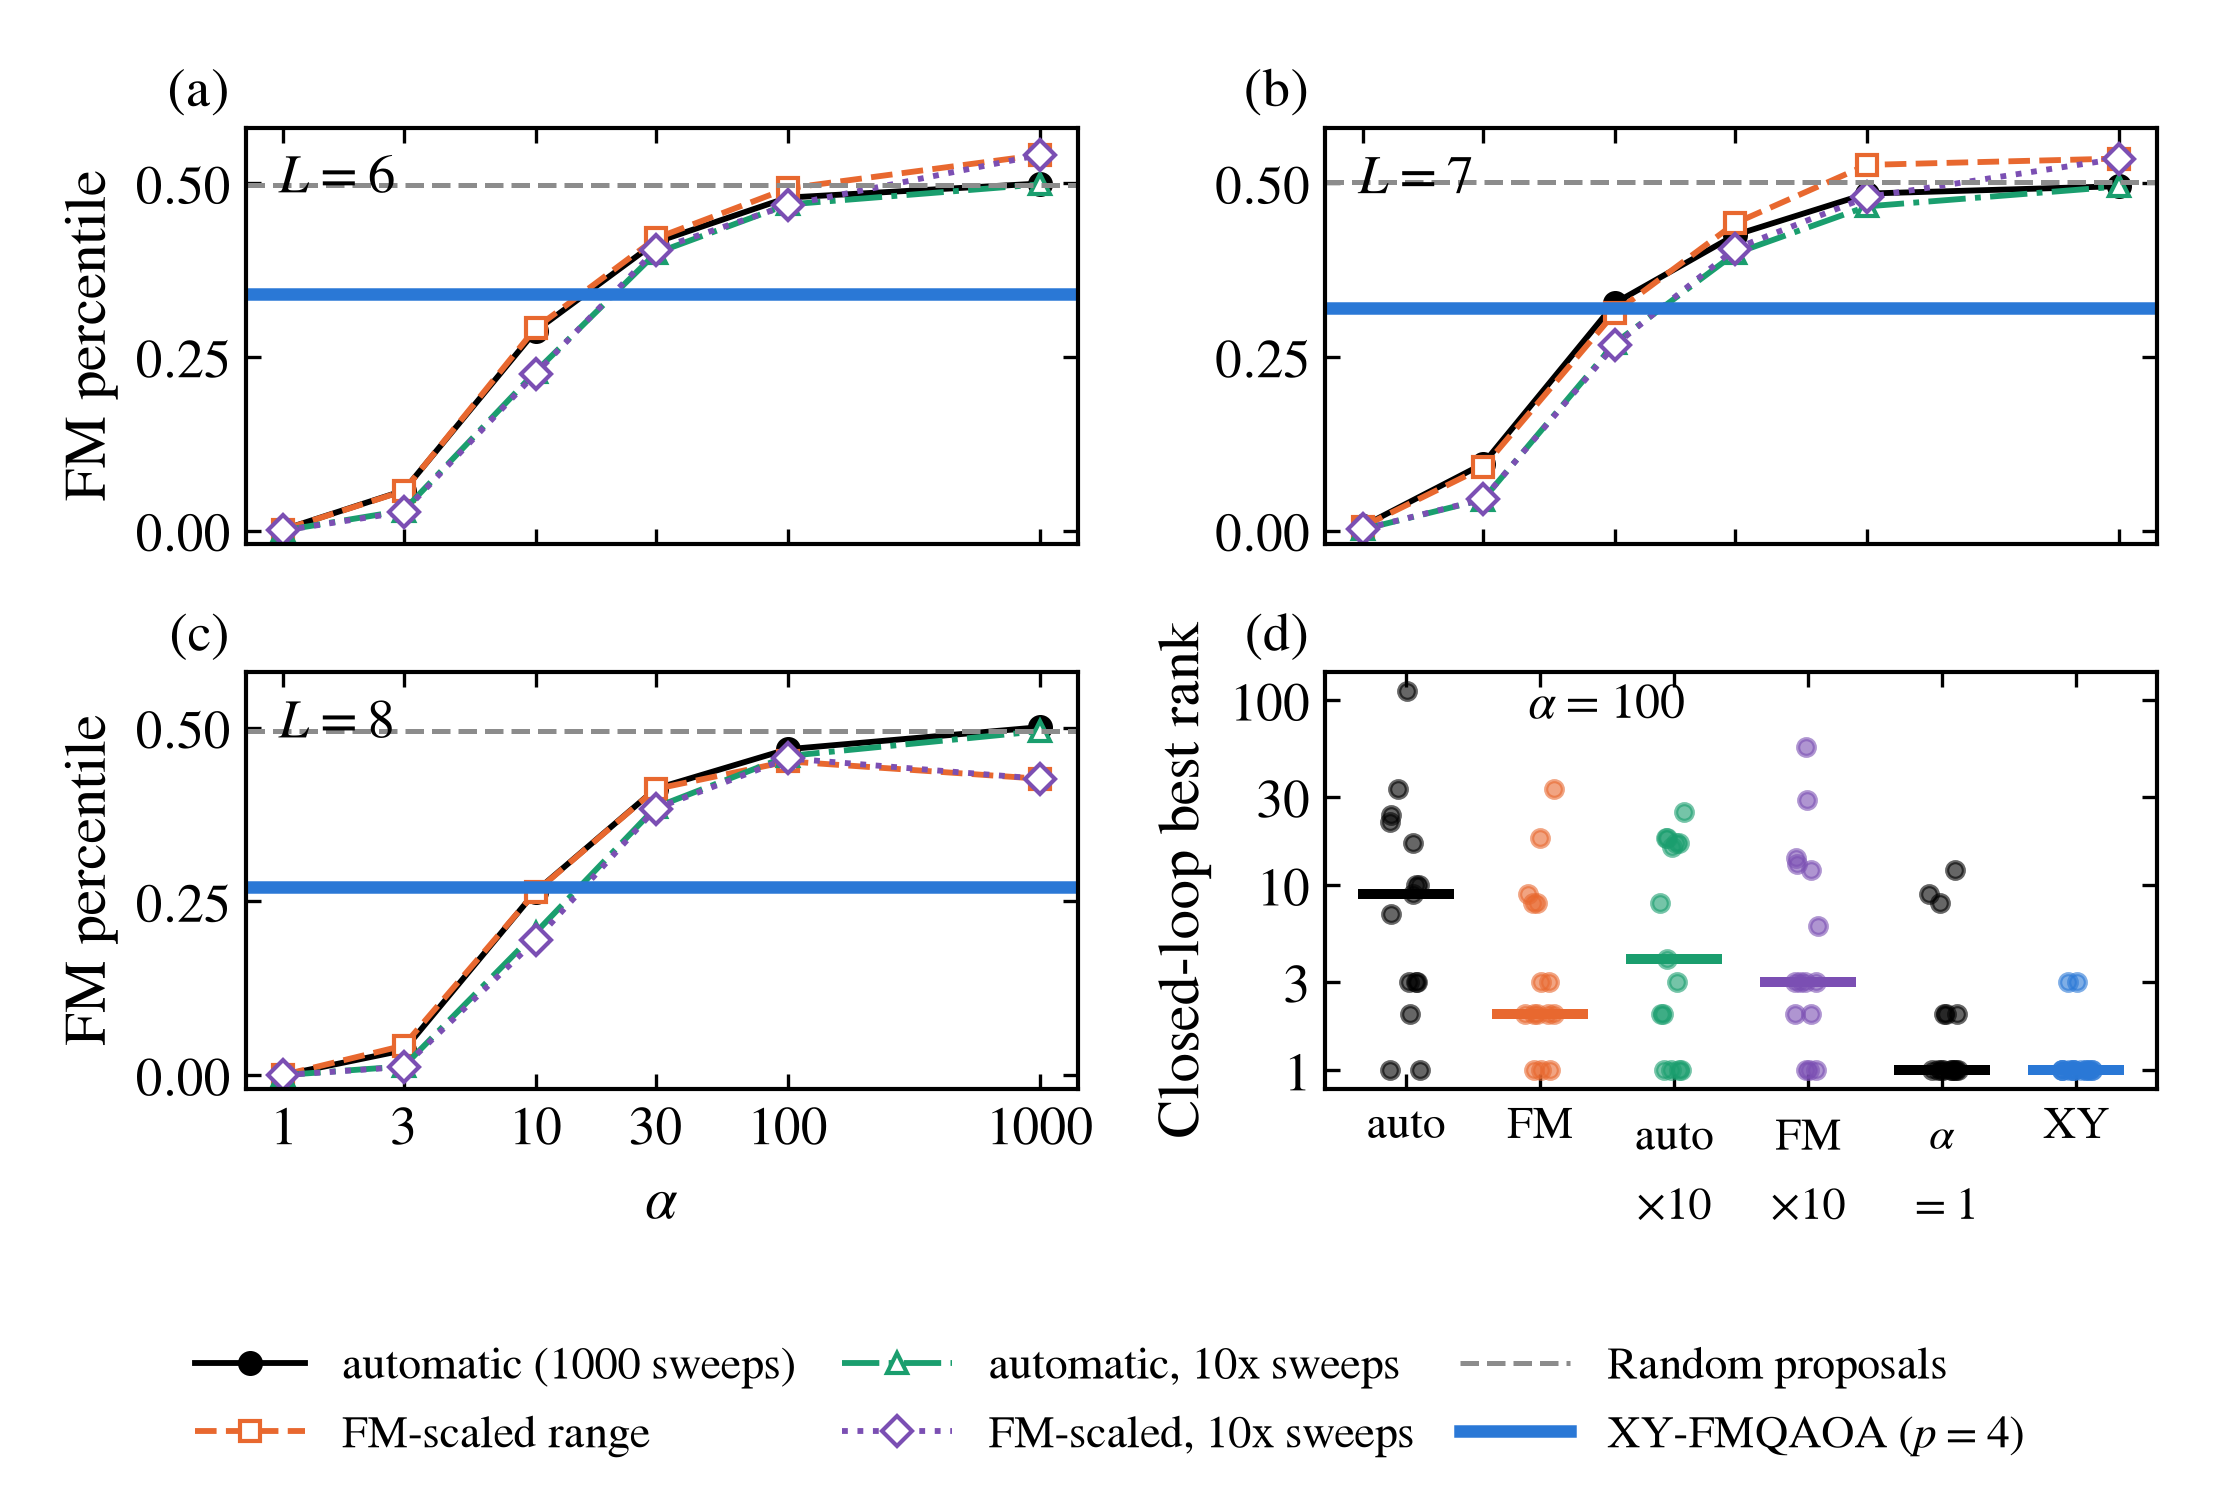

In [7]:
rows = read_csv("fixedfm_sa_schedule_retune.csv")
loop = read_csv("closedloop_l7_schedule_retune.csv")
SCHEDULE_STYLE = {
    "auto": dict(color="black", ls="-", marker="o"),
    "fmscale": dict(color=ORANGE, ls="--", marker="s", mfc="white"),
    "wide10x": dict(color=GREEN, ls="-.", marker="^", mfc="white"),
    "fmscale10x": dict(color=PURPLE, ls=":", marker="D", mfc="white"),
}
SCHEDULE_LABEL = {
    "auto": "automatic (1000 sweeps)",
    "fmscale": "FM-scaled range",
    "wide10x": "automatic, 10x sweeps",
    "fmscale10x": "FM-scaled, 10x sweeps",
}
alphas = [1, 3, 10, 30, 100, 1000]

with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(2, 2, figsize=(FW, FH))
    axes = axes.ravel()
    for ax, L in zip(axes[:3], (6, 7, 8)):
        for sch, st in SCHEDULE_STYLE.items():
            r = {x["alpha"]: x["sample_fm_pct_median"] for x in rows if x["layers"] == L and x["series"] == f"SA-{sch}"}
            ax.plot(alphas, [np.nan if r[a] is None else r[a] for a in alphas], label=SCHEDULE_LABEL[sch], ms=5, lw=1.4, **st)
        ref = {x["series"]: x["sample_fm_pct_median"] for x in rows if x["layers"] == L and x["alpha"] is None}
        ax.axhline(ref["RandomFM"], color=GRAY, ls="--", lw=1.2, label="Random proposals")
        ax.axhline(ref["XY-p4-cvar10"], color=BLUE, lw=3.0, label="XY-FMQAOA ($p=4$)")
        ax.set_xscale("log")
        log_ticks(ax.xaxis, alphas)
        ax.set_ylim(-0.02, 0.58)
        ax.set_yticks([0, 0.25, 0.5])
        ax.text(0.04, 0.94, f"$L={L}$", transform=ax.transAxes, ha="left", va="top", fontsize=13)
    for ax in axes[:2]:
        ax.tick_params(labelbottom=False)
    axes[2].set_xlabel("$\\alpha$")
    axes[0].set_ylabel("FM percentile")
    axes[2].set_ylabel("FM percentile")

    conds = [
        ("alpha100", "auto"),
        ("alpha100-fmscale", "fmscale"),
        ("alpha100-wide10x", "wide10x"),
        ("alpha100-fmscale10x", "fmscale10x"),
        ("alpha1", None),
        ("XY-FMQAOA", None),
    ]
    ax = axes[3]
    for i, (c, sch) in enumerate(conds):
        v = [r["best_rank"] for r in loop if r["condition"] == c]
        col = SCHEDULE_STYLE[sch]["color"] if sch else M[c]["color"]
        ax.plot([i] * len(v) + 0.12 * np.random.default_rng(i).uniform(-1, 1, len(v)), v, "o", ms=4, color=col, alpha=0.6)
        ax.plot([i - 0.32, i + 0.32], [np.median(v)] * 2, color=col, lw=2.4)
    ax.set_xticks(range(len(conds)))
    ax.set_xticklabels(["auto", "FM", "auto\n×10", "FM\n×10", "$\\alpha$\n$=1$", "XY"], fontsize=11)
    ax.set_yscale("log")
    log_ticks(ax.yaxis, [1, 3, 10, 30, 100])
    ax.set_ylabel("Closed-loop best rank")
    ax.text(1.5, 0.98, "$\\alpha=100$", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=12)
    letters(axes)
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, fontsize=11, handlelength=2.4, columnspacing=1.0)
    fig.tight_layout(rect=(0, 0.13, 1, 1), h_pad=0.8, w_pad=1.0)
    save_and_show(fig, "sa_schedule_retune_robustness")


## 7. 閉ループ BBO: 第1確認実験の Seed ごとの対応（$L=7$, 15 seeds）


Saved: results/figures/png/closedloop_l7_paired_ranks.png, results/figures/pdf/closedloop_l7_paired_ranks.pdf


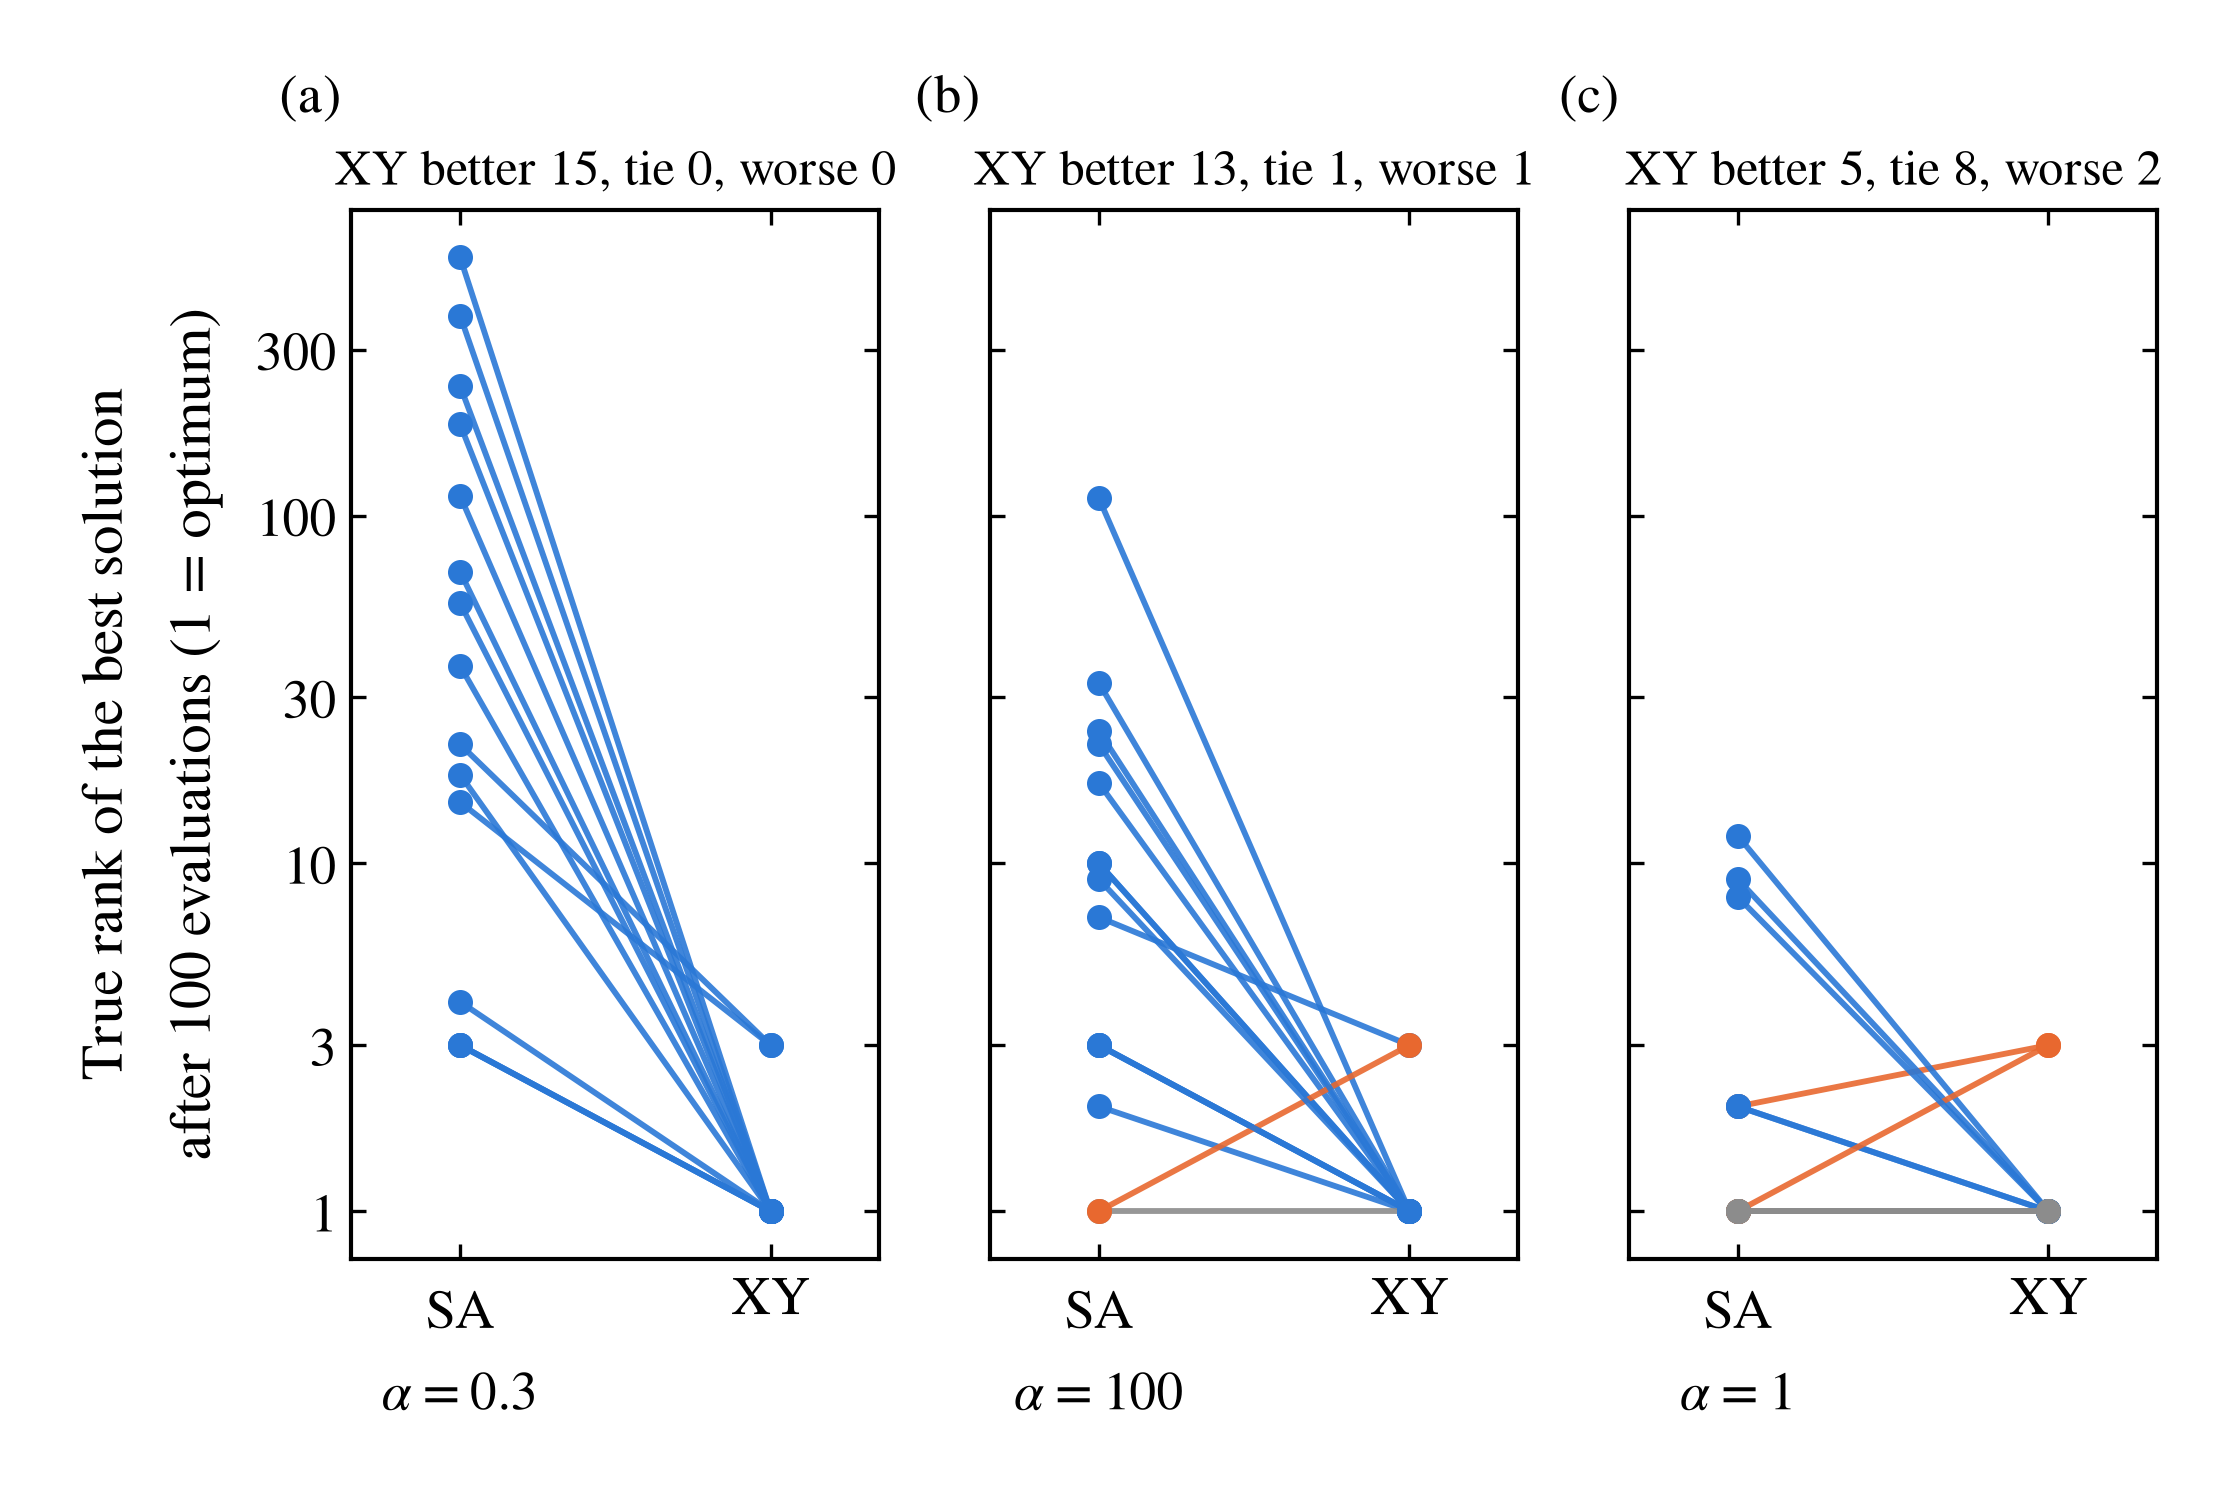

In [8]:
rows = read_csv("closedloop_l7_paired_ranks.csv")
CMP_LABEL = {"alpha0.3": "SA\n$\\alpha=0.3$", "alpha100": "SA\n$\\alpha=100$", "alpha1": "SA\n$\\alpha=1$"}
color = {"xy_better": BLUE, "tie": GRAY, "xy_worse": ORANGE}
with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 3, figsize=(FW, FH), sharey=True)
    for ax, c in zip(axes, ("alpha0.3", "alpha100", "alpha1")):
        r = sorted((x for x in rows if x["comparator"] == c), key=lambda x: x["seed"])
        for x in r:
            col = color[x["outcome"]]
            ax.plot([0, 1], [x["comparator_rank"], x["xy_rank"]], "-", color=col, lw=1.4, alpha=0.9)
            ax.plot([0, 1], [x["comparator_rank"], x["xy_rank"]], "o", color=col, ms=5)
        n = {k: sum(x["outcome"] == k for x in r) for k in color}
        ax.set_title(f"XY better {n['xy_better']}, tie {n['tie']}, worse {n['xy_worse']}", fontsize=12)
        ax.set_xticks([0, 1])
        ax.set_xticklabels([CMP_LABEL[c], "XY"])
        ax.set_xlim(-0.35, 1.35)
        ax.set_yscale("log")
        log_ticks(ax.yaxis, [1, 3, 10, 30, 100, 300])
    axes[0].set_ylabel("True rank of the best solution\nafter 100 evaluations (1 = optimum)")
    letters(axes, y=1.08)
    fig.tight_layout(w_pad=0.6)
    save_and_show(fig, "closedloop_l7_paired_ranks")


## 8. 閉ループ BBO: 探索段階の閉ループ推移（$L=6, 7, 8$, 5 seeds）


Saved: results/figures/png/closedloop_l678_explore_5seeds.png, results/figures/pdf/closedloop_l678_explore_5seeds.pdf


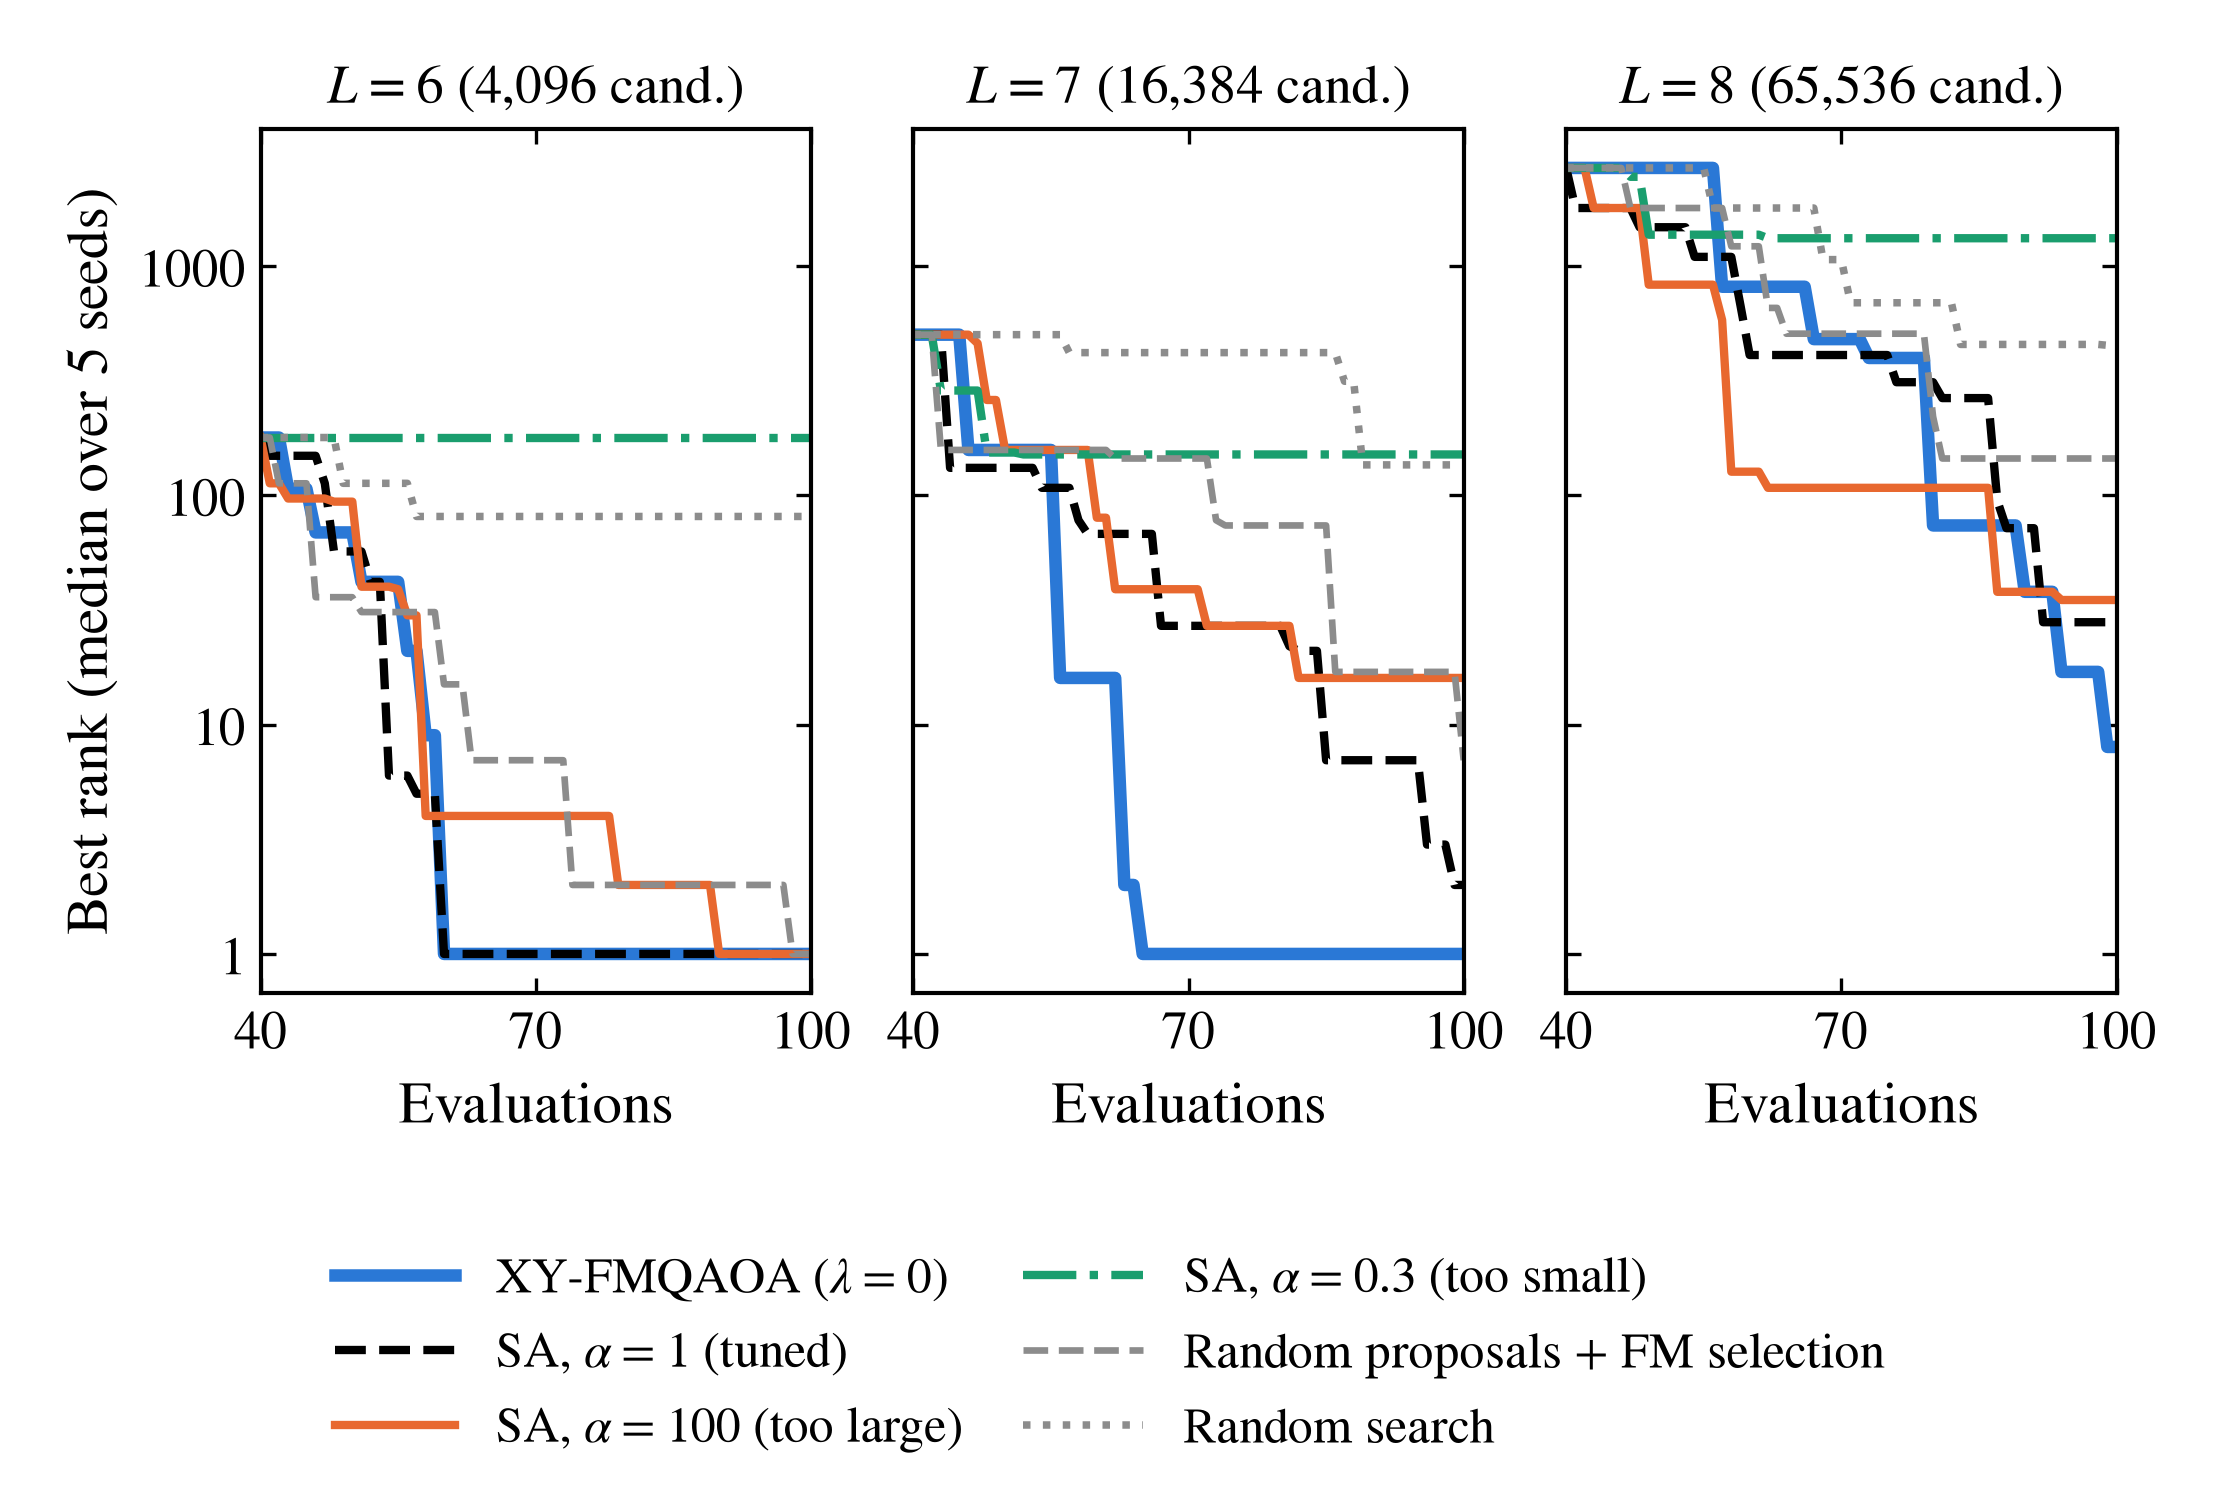

In [9]:
rows = read_csv("closedloop_l678_explore_5seeds.csv")
with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 3, figsize=(FW, FH), sharey=True)
    for ax, L in zip(axes, (6, 7, 8)):
        for c in ("XY-FMQAOA", "alpha1", "alpha100", "alpha0.3", "RandomFM", "Random"):
            r = sorted((x for x in rows if x["layers"] == L and x["condition"] == c), key=lambda x: x["evaluations"])
            if r:
                st = M[c]
                ax.plot([x["evaluations"] for x in r], [x["best_rank_median"] for x in r], color=st["color"], ls=st["ls"], lw=st["lw"], label=st["label"])
        ax.set_yscale("log")
        log_ticks(ax.yaxis, [1, 10, 100, 1000])
        ax.set_xlim(40, 100)
        ax.set_xticks([40, 70, 100])
        ax.set_xlabel("Evaluations")
        ax.set_title(f"$L={L}$ ({NCAND[L]} cand.)", fontsize=13)
    axes[0].set_ylabel("Best rank (median over 5 seeds)")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, fontsize=12, handlelength=2.4, columnspacing=1.2)
    fig.tight_layout(rect=(0, 0.2, 1, 1), w_pad=0.6)
    save_and_show(fig, "closedloop_l678_explore_5seeds")


## 9. 固定 FM: SA の `reads` 数を増やした場合の挙動（固定 FM, $L=7$）


Saved: results/figures/png/fixedfm_l7_sa_reads_sweep.png, results/figures/pdf/fixedfm_l7_sa_reads_sweep.pdf


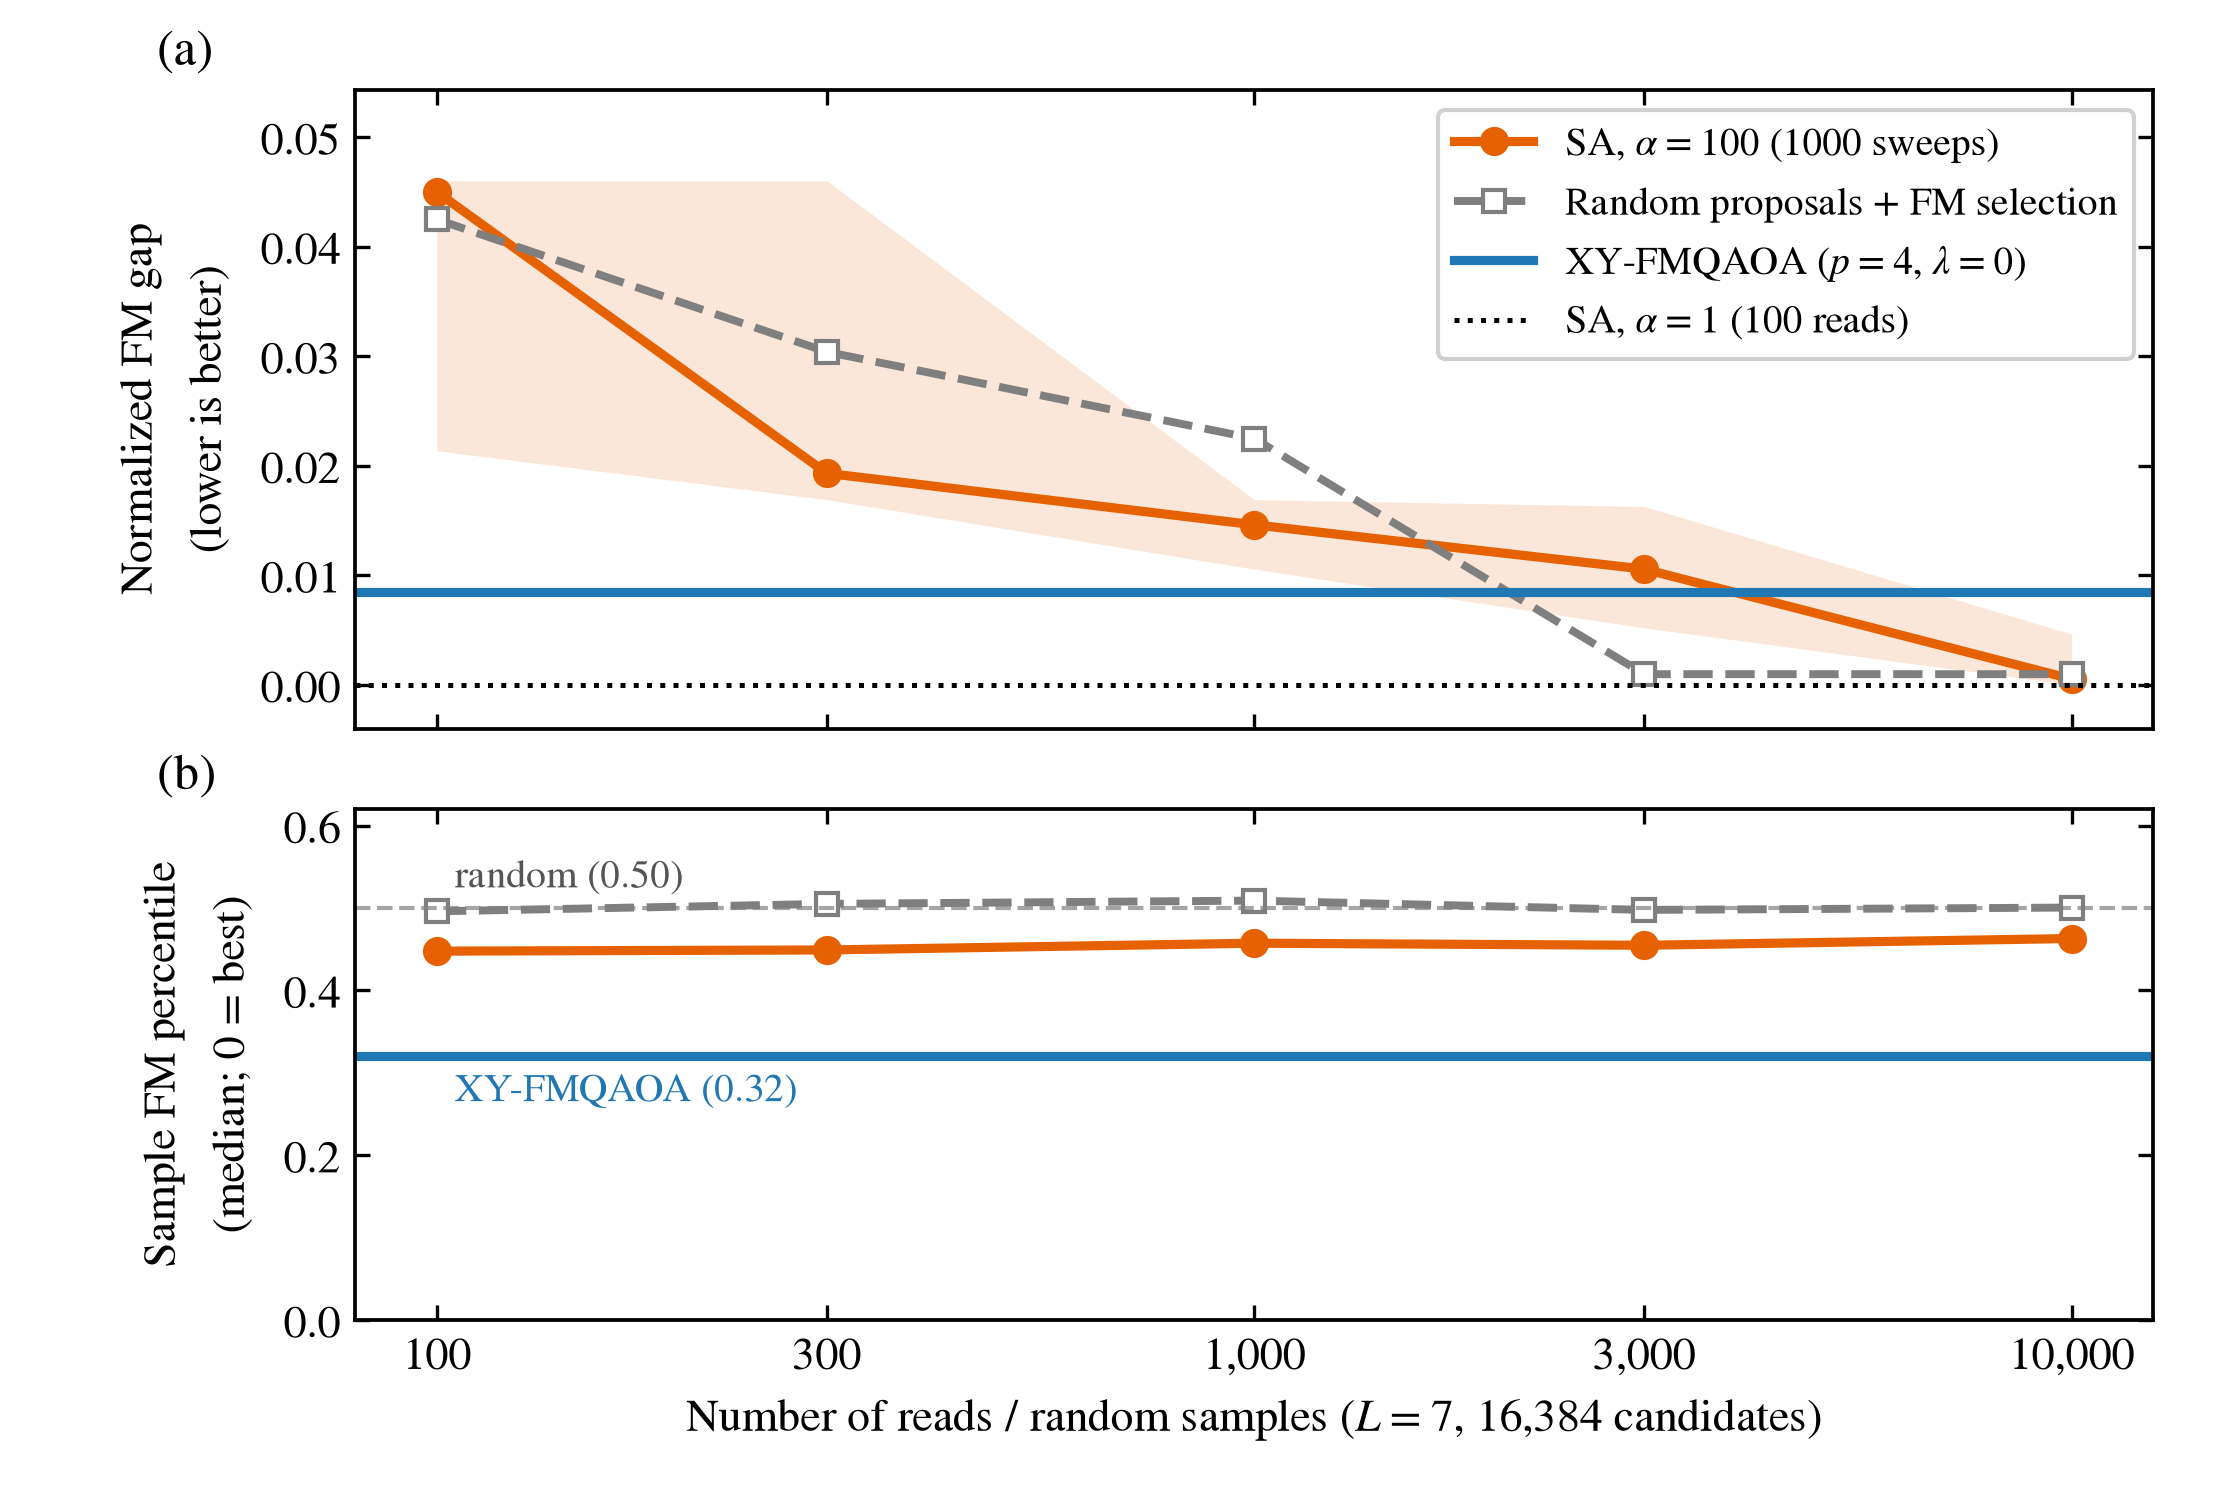

In [10]:
rows = read_csv("fixedfm_l7_sa_reads_sweep.csv")
sa_rows = sorted((r for r in rows if r["method"] == "SA_a100"), key=lambda r: r["reads"])
rd_rows = sorted((r for r in rows if r["method"] == "RandomFM"), key=lambda r: r["reads"])
xs = np.array([r["reads"] for r in sa_rows], dtype=float)

# Reference values for L=7 XY-FMQAOA (p=4)
depth_rows = read_csv("fixedfm_xy_depth_sweep.csv")
XY_P4_GAP = next(r["norm_gap_median"] for r in depth_rows if r["layers"] == 7 and r["method"] == "XY-FMQAOA" and r["p"] == 4)
retune_rows = read_csv("fixedfm_sa_schedule_retune.csv")
XY_P4_PCT = next(r["sample_fm_pct_median"] for r in retune_rows if r["layers"] == 7 and r["series"] == "XY-p4-cvar10")

READS_RC = {**SLIDE_RC, "font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11, "axes.linewidth": 0.9}
with plt.rc_context(READS_RC):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(FW, FH), sharex=True, gridspec_kw={"height_ratios": [1.25, 1.0], "hspace": 0.14})
    sa_g_med = [r["gap_median"] for r in sa_rows]
    sa_g_q25 = [r["gap_q25"] for r in sa_rows]
    sa_g_q75 = [r["gap_q75"] for r in sa_rows]
    rd_g_med = [r["gap_median"] for r in rd_rows]

    ax1.fill_between(xs, sa_g_q25, sa_g_q75, color="#E66101", alpha=0.15, lw=0)
    ax1.plot(xs, sa_g_med, "-o", color="#E66101", lw=2.2, ms=6, label=r"SA, $\alpha=100$ (1000 sweeps)")
    ax1.plot(xs, rd_g_med, "--s", color="#7F7F7F", lw=1.9, ms=5.5, mfc="white", label="Random proposals + FM selection")
    ax1.axhline(XY_P4_GAP, color="#1F77B4", lw=2.2, label=r"XY-FMQAOA ($p=4$, $\lambda=0$)")
    ax1.axhline(0.0, color="black", lw=1.2, ls=":", label=r"SA, $\alpha=1$ (100 reads)")
    ax1.set_ylabel("Normalized FM gap\n(lower is better)")
    ax1.set_ylim(-0.004, max(max(sa_g_q75), max(rd_g_med)) * 1.18)
    ax1.text(-0.11, 1.04, "(a)", transform=ax1.transAxes, fontsize=12)
    ax1.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, edgecolor="#CCCCCC", fontsize=9.5)

    ax2.plot(xs, [r["pct_median"] for r in sa_rows], "-o", color="#E66101", lw=2.2, ms=6)
    ax2.plot(xs, [r["pct_median"] for r in rd_rows], "--s", color="#7F7F7F", lw=1.9, ms=5.5, mfc="white")
    ax2.axhline(0.5, color="#7F7F7F", lw=1.0, ls="--", alpha=0.7)
    ax2.axhline(XY_P4_PCT, color="#1F77B4", lw=2.2)
    ax2.text(105, 0.525, "random (0.50)", color="#555555", fontsize=9.5)
    ax2.text(105, XY_P4_PCT - 0.055, f"XY-FMQAOA ({XY_P4_PCT:.2f})", color="#1F77B4", fontsize=9.5)
    ax2.set_ylabel("Sample FM percentile\n(median; 0 = best)")
    ax2.set_xlabel("Number of reads / random samples ($L=7$, 16,384 candidates)")
    ax2.set_xscale("log")
    ax2.set_xticks(xs)
    ax2.set_xticklabels([f"{int(r):,}" for r in xs])
    ax2.minorticks_off()
    ax2.set_ylim(0.0, 0.62)
    ax2.text(-0.11, 1.04, "(b)", transform=ax2.transAxes, fontsize=12)

    fig.subplots_adjust(left=0.16, right=0.97, top=0.94, bottom=0.12)
    save_and_show(fig, "fixedfm_l7_sa_reads_sweep")


## 10. OpenQARP による XY-QAOA 回路図の生成

`openqarp` がインストールされている環境では、P.14 に掲載している XY-QAOA 回路図（全体ブロックおよび XY ミキサーのゲート分解）をそのまま再現できます。未導入環境ではスキップされます。


findfont: Failed to find font weight light for Spline Sans Mono, now using 400.


findfont: Failed to find font weight light for DejaVu Sans Mono, now using 400.


Saved: results/figures/png/openqarp_xy_qaoa_macro.png, results/figures/pdf/openqarp_xy_qaoa_macro.pdf


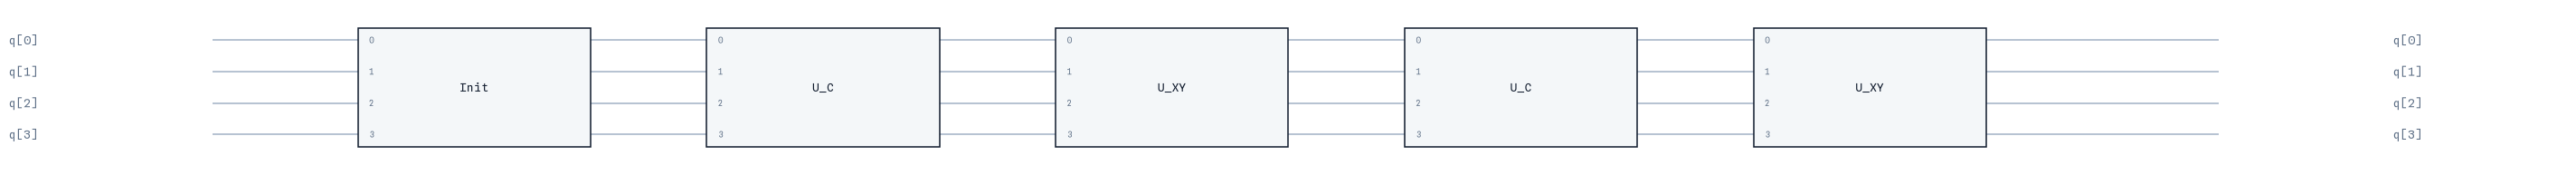

Saved: results/figures/png/openqarp_xy_mixer_decomp.png, results/figures/pdf/openqarp_xy_mixer_decomp.pdf


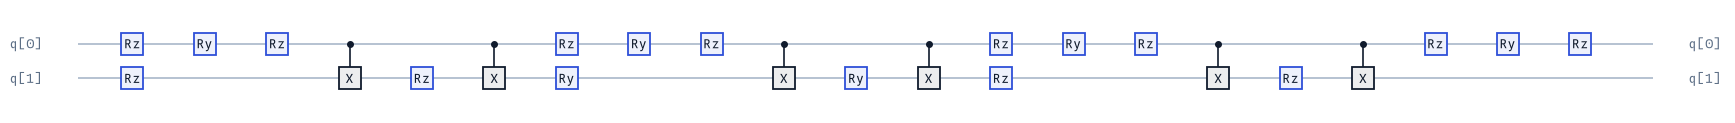

In [11]:
try:
    from scipy.linalg import expm
    from qarpx import CompositeBlock, SimpleBlock
    from qarp.plotting import LabelMode, plot as qarp_plot

    # 1-layer (2-qubit compact encoding) XY ring mixer generator H_XY
    H_xy = np.array(
        [[0, 1, 0, 1], [1, 0, 1, 0], [0, 1, 0, 1], [1, 0, 1, 0]],
        dtype=np.complex128,
    )
    beta_sample = 0.35
    U_xy = np.asfortranarray(expm(-1j * beta_sample * H_xy))

    # (a) Macro XY-QAOA circuit (L=2 layers -> 4 qubits, p=2)
    init_blk = SimpleBlock(4, name="Init")
    for q in range(4):
        init_blk.h(q)
    init_blk.build()
    children = [init_blk]
    rng = np.random.default_rng(42)
    for layer_idx in range(1, 3):
        cost_blk = SimpleBlock(4, name=f"U_C({layer_idx})")
        cost_blk.diagonal_unitary(np.exp(-1j * 0.4 * rng.standard_normal(16)).tolist())
        cost_blk.build()
        mix_l0 = SimpleBlock(2, name="XY")
        mix_l0.unitary_synthesis(U_xy)
        cmds = []
        for cmd in mix_l0.commands():
            cmds.append(cmd.remap_qubits([0, 1]))
            cmds.append(cmd.remap_qubits([2, 3]))
        mix_blk = SimpleBlock(4, name=f"U_XY({layer_idx})")
        mix_blk.set_commands(cmds)
        mix_blk.build()
        children.extend([cost_blk, mix_blk])
    macro = CompositeBlock(children, n_qubits=4, name="XY-QAOA (L=2, p=2)")
    macro.build()

    def _save_qarp(circ, stem: str, spacing: float | None = None) -> None:
        png_path = FIG_DIR / "png" / f"{stem}.png"
        pdf_path = FIG_DIR / "pdf" / f"{stem}.pdf"
        kw = {"label_mode": LabelMode.TRUNCATE, "_show": False}
        if spacing is not None:
            kw["spacing"] = spacing
        qarp_plot(circ, save_fig=str(png_path), **kw)
        qarp_plot(circ, save_fig=str(pdf_path), **kw)
        print(f"Saved: {png_path.relative_to(ROOT)}, {pdf_path.relative_to(ROOT)}")
        display(IPImage(filename=str(png_path), width=720))

    _save_qarp(macro, "openqarp_xy_qaoa_macro", spacing=1.6)

    # (b) Gate decomposition of 1-layer XY ring mixer (2 qubits)
    dec_blk = SimpleBlock(2, name="1-Layer XY Mixer")
    dec_blk.unitary_synthesis(U_xy)
    _save_qarp(dec_blk, "openqarp_xy_mixer_decomp")
except ImportError:
    print("openqarp is not installed; skipping P.14 circuit diagram generation.")


## 数値サマリー確認

CSV から集計した主要指標（最適解到達 Seed 数など）がスライド記載と一致することを確認します。


In [12]:
r18 = {r["condition"]: r for r in read_csv("closedloop_l7_alpha_sweep.csv")}
print("Closed-loop alpha sweep (L=7, 15 seeds) optimum reached:")
for c in ("XY-FMQAOA", "alpha1", "alpha10", "alpha100", "alpha1000", "Adaptive", "RandomFM"):
    print(f"  {c:12s}: {int(r18[c]['n_optimum']):2d}/15 (median rank={r18[c]['best_rank_median']:.1f})")

fin = {}
for r in read_csv("closedloop_l678_fom_curves.csv"):
    k = (int(r["layers"]), r["condition"])
    if k not in fin or r["cycle"] > fin[k]["cycle"]:
        fin[k] = r

print("\nClosed-loop unified comparison (L=6,7,8, 30 seeds) optimum reached:")
for L in (6, 7, 8):
    vals = [f"{c}={int(fin[(L, c)]['n_optimum'])}/{int(fin[(L, c)]['n_seeds'])}" for c in ("XY-FMQAOA", "alpha1", "alpha100", "alpha0.3", "RandomFM", "Random")]
    print(f"  L={L}: " + ", ".join(vals))


Closed-loop alpha sweep (L=7, 15 seeds) optimum reached:
  XY-FMQAOA   : 13/15 (median rank=1.0)
  alpha1      :  9/15 (median rank=1.0)
  alpha10     :  4/15 (median rank=7.0)
  alpha100    :  2/15 (median rank=9.0)
  alpha1000   :  4/15 (median rank=7.0)
  Adaptive    :  8/15 (median rank=1.0)
  RandomFM    :  1/15 (median rank=7.0)

Closed-loop unified comparison (L=6,7,8, 30 seeds) optimum reached:
  L=6: XY-FMQAOA=30/30, alpha1=29/30, alpha100=23/30, alpha0.3=3/30, RandomFM=19/30, Random=0/30
  L=7: XY-FMQAOA=23/30, alpha1=18/30, alpha100=4/30, alpha0.3=2/30, RandomFM=3/30, Random=0/30
  L=8: XY-FMQAOA=16/30, alpha1=13/30, alpha100=3/30, alpha0.3=1/30, RandomFM=3/30, Random=0/30
